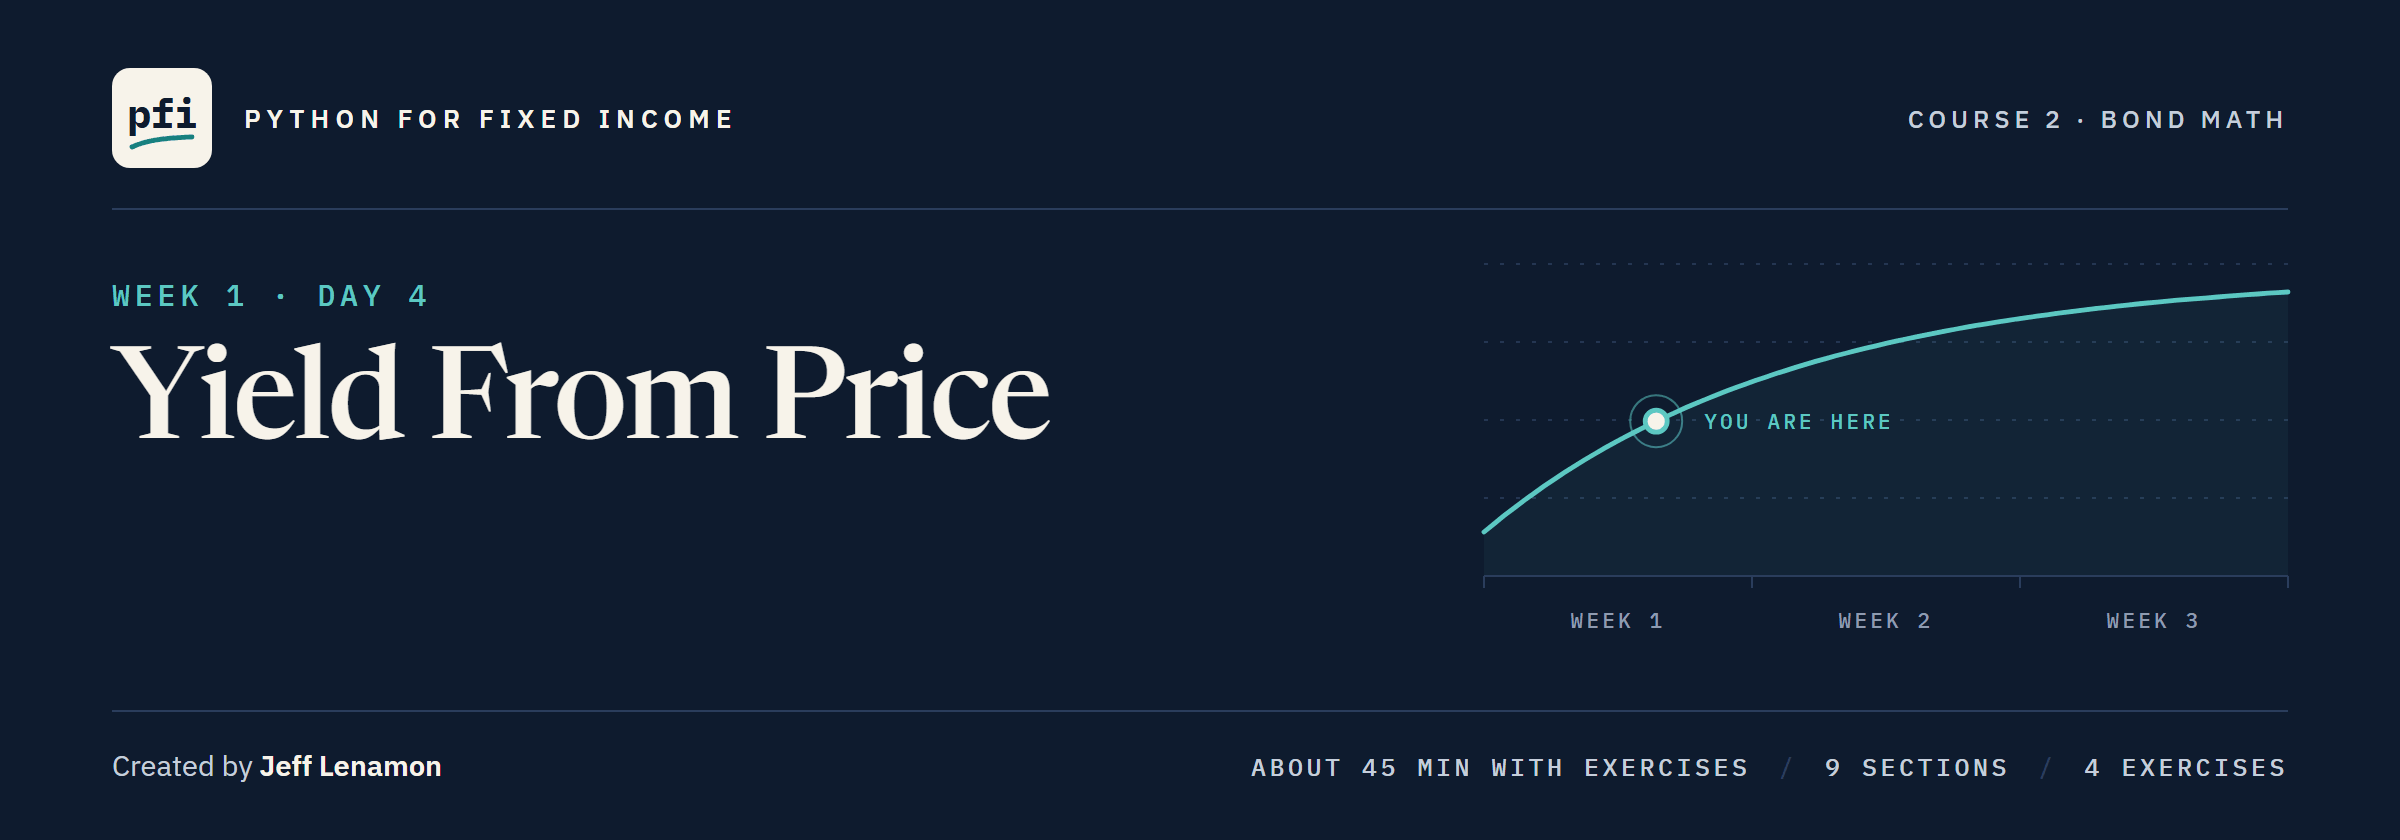

# Yield From Price

Week 1, Day 4. A quoted price turned back into its yield by a search that halves a bracket, checked against Excel's Goal Seek, `RATE` and `YIELD`, tested for the prices it must refuse, and a bad edit undone with Git.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day4/04_yield_from_price.ipynb)

### The Desk Lead's Note

> Dealers quote the four new bonds on price this morning: Quorvane 99.125, Dunmarrow 100.5, Pellwick 100.875, Halvering 97.75. Notebook 02 went from yield to price; I need the other way. What yield does each quote imply? Show me how Excel gets there and how close it lands. Put the search in `bondmath`, docstring first, prove it against Excel's RATE and YIELD, and make it refuse a price no yield explains. If an edit breaks it, show me you can undo it, then take it home.

The issuers and quotes are invented; every number describes the data.

### Start the Day

As in notebook 03, the setup makes a new work folder holding the module, its tests, and the first three commits, and pytest gives the starting count.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 03 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(4)

Work folder pfi_course2_04_k4w7q2xr: 2 data files, the module as notebook 03 left it, 3 commits


In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........                                                                 [100%]
8 passed in 0.50s



### Imports and the House Colours

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import bondmath

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

### Four Bonds, Quoted on Price

In [4]:
bonds = pd.DataFrame({
    'issuer': ['Quorvane Energy', 'Dunmarrow Rail', 'Pellwick Paper', 'Halvering Foods'],
    'ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'coupon_pct': [5.25, 6.125, 4.75, 7.5],
    'years': [5, 7, 3, 10],
    # this morning's quoted prices, per 100 of face
    'quote': [99.125, 100.5, 100.875, 97.75],
})
bonds

,issuer,ticker,coupon_pct,years,quote
0,Quorvane Energy,QVNE,5.250,5,99.125
1,Dunmarrow Rail,DNMR,6.125,7,100.500
2,Pellwick Paper,PLWK,4.750,3,100.875
3,Halvering Foods,HLVF,7.500,10,97.750


No yield column: finding it is today's job.
Dunmarrow and Pellwick are quoted above 100, so notebook 03's rule already says they yield less than their coupons.

**Four prices, no yields: today the arrow turns.**

## Your Route Through Day 4

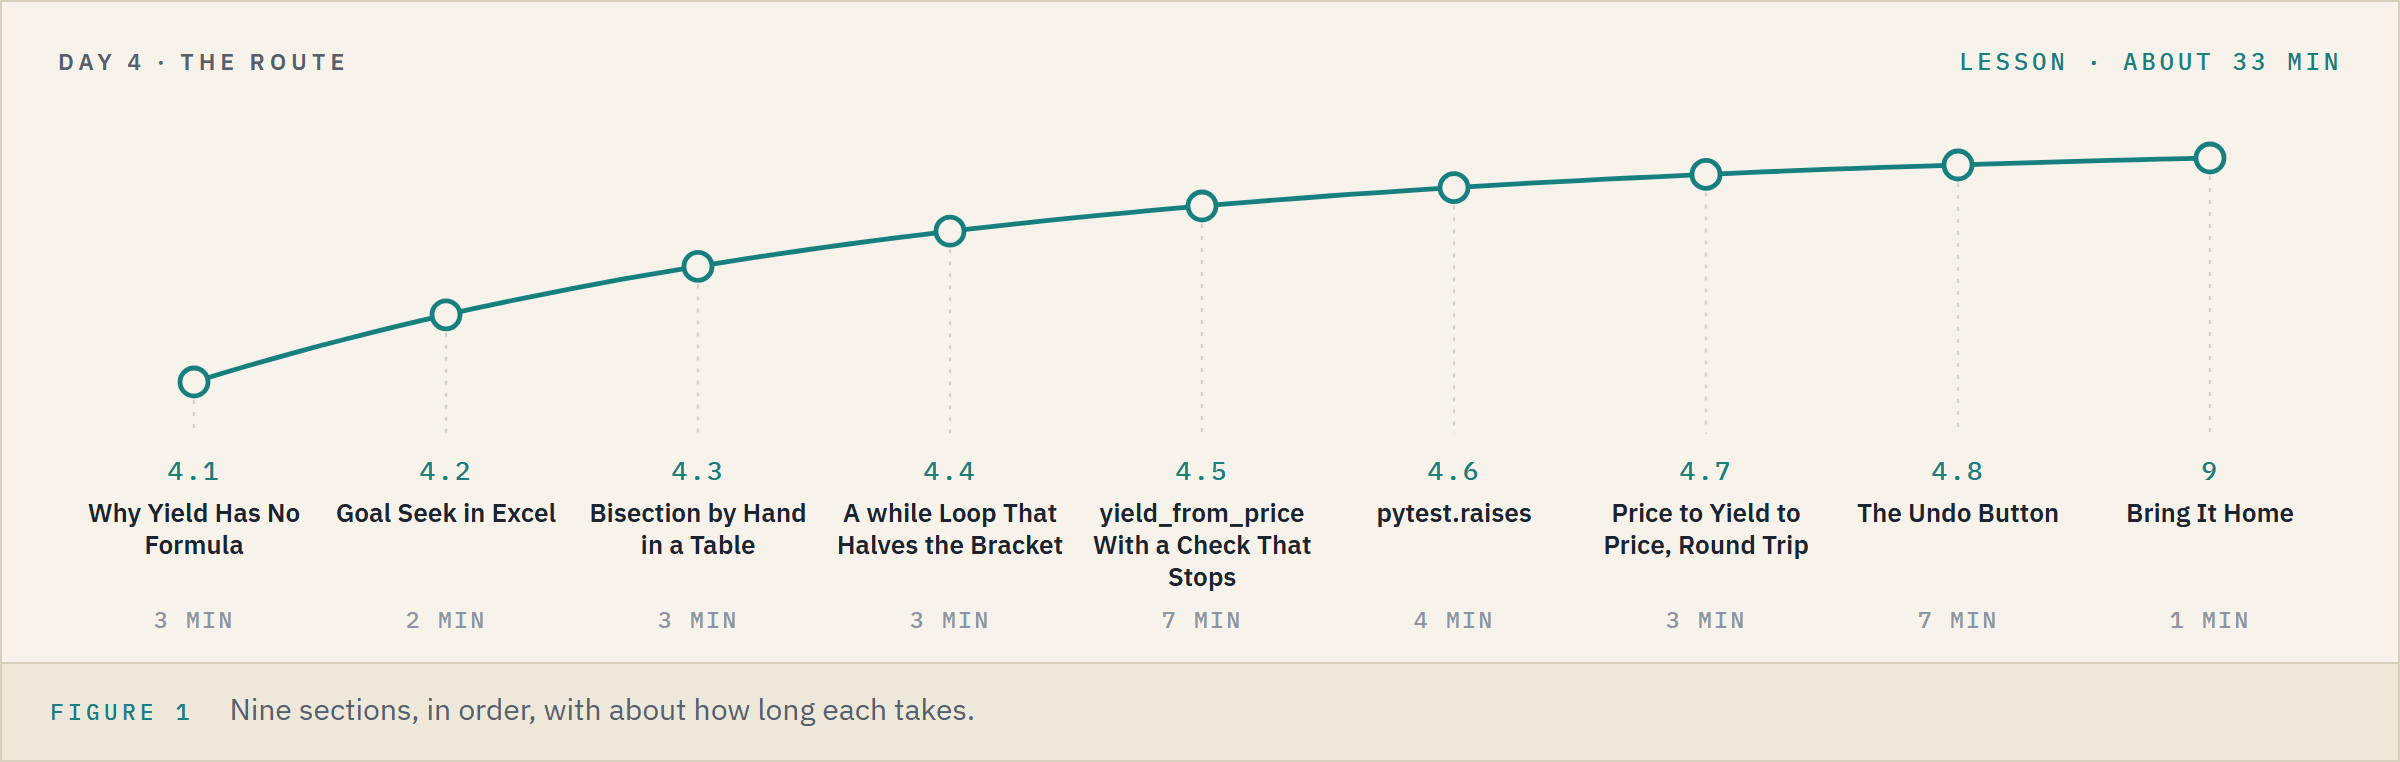

**Time.** About 33 minutes for the lesson, then about 12 for the four exercises.

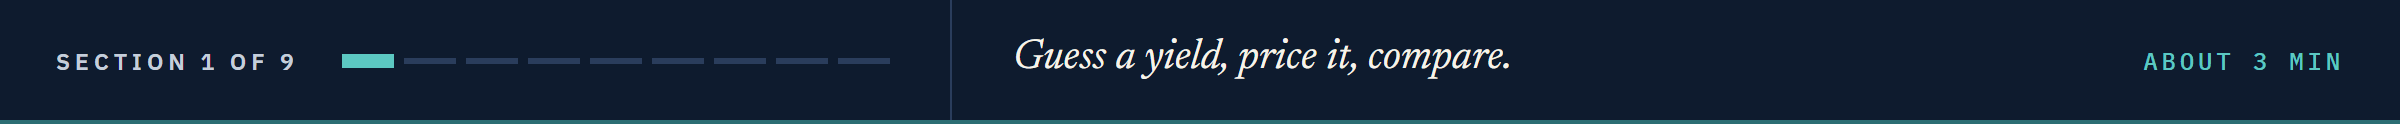

## 4.1 Why Yield Has No Formula

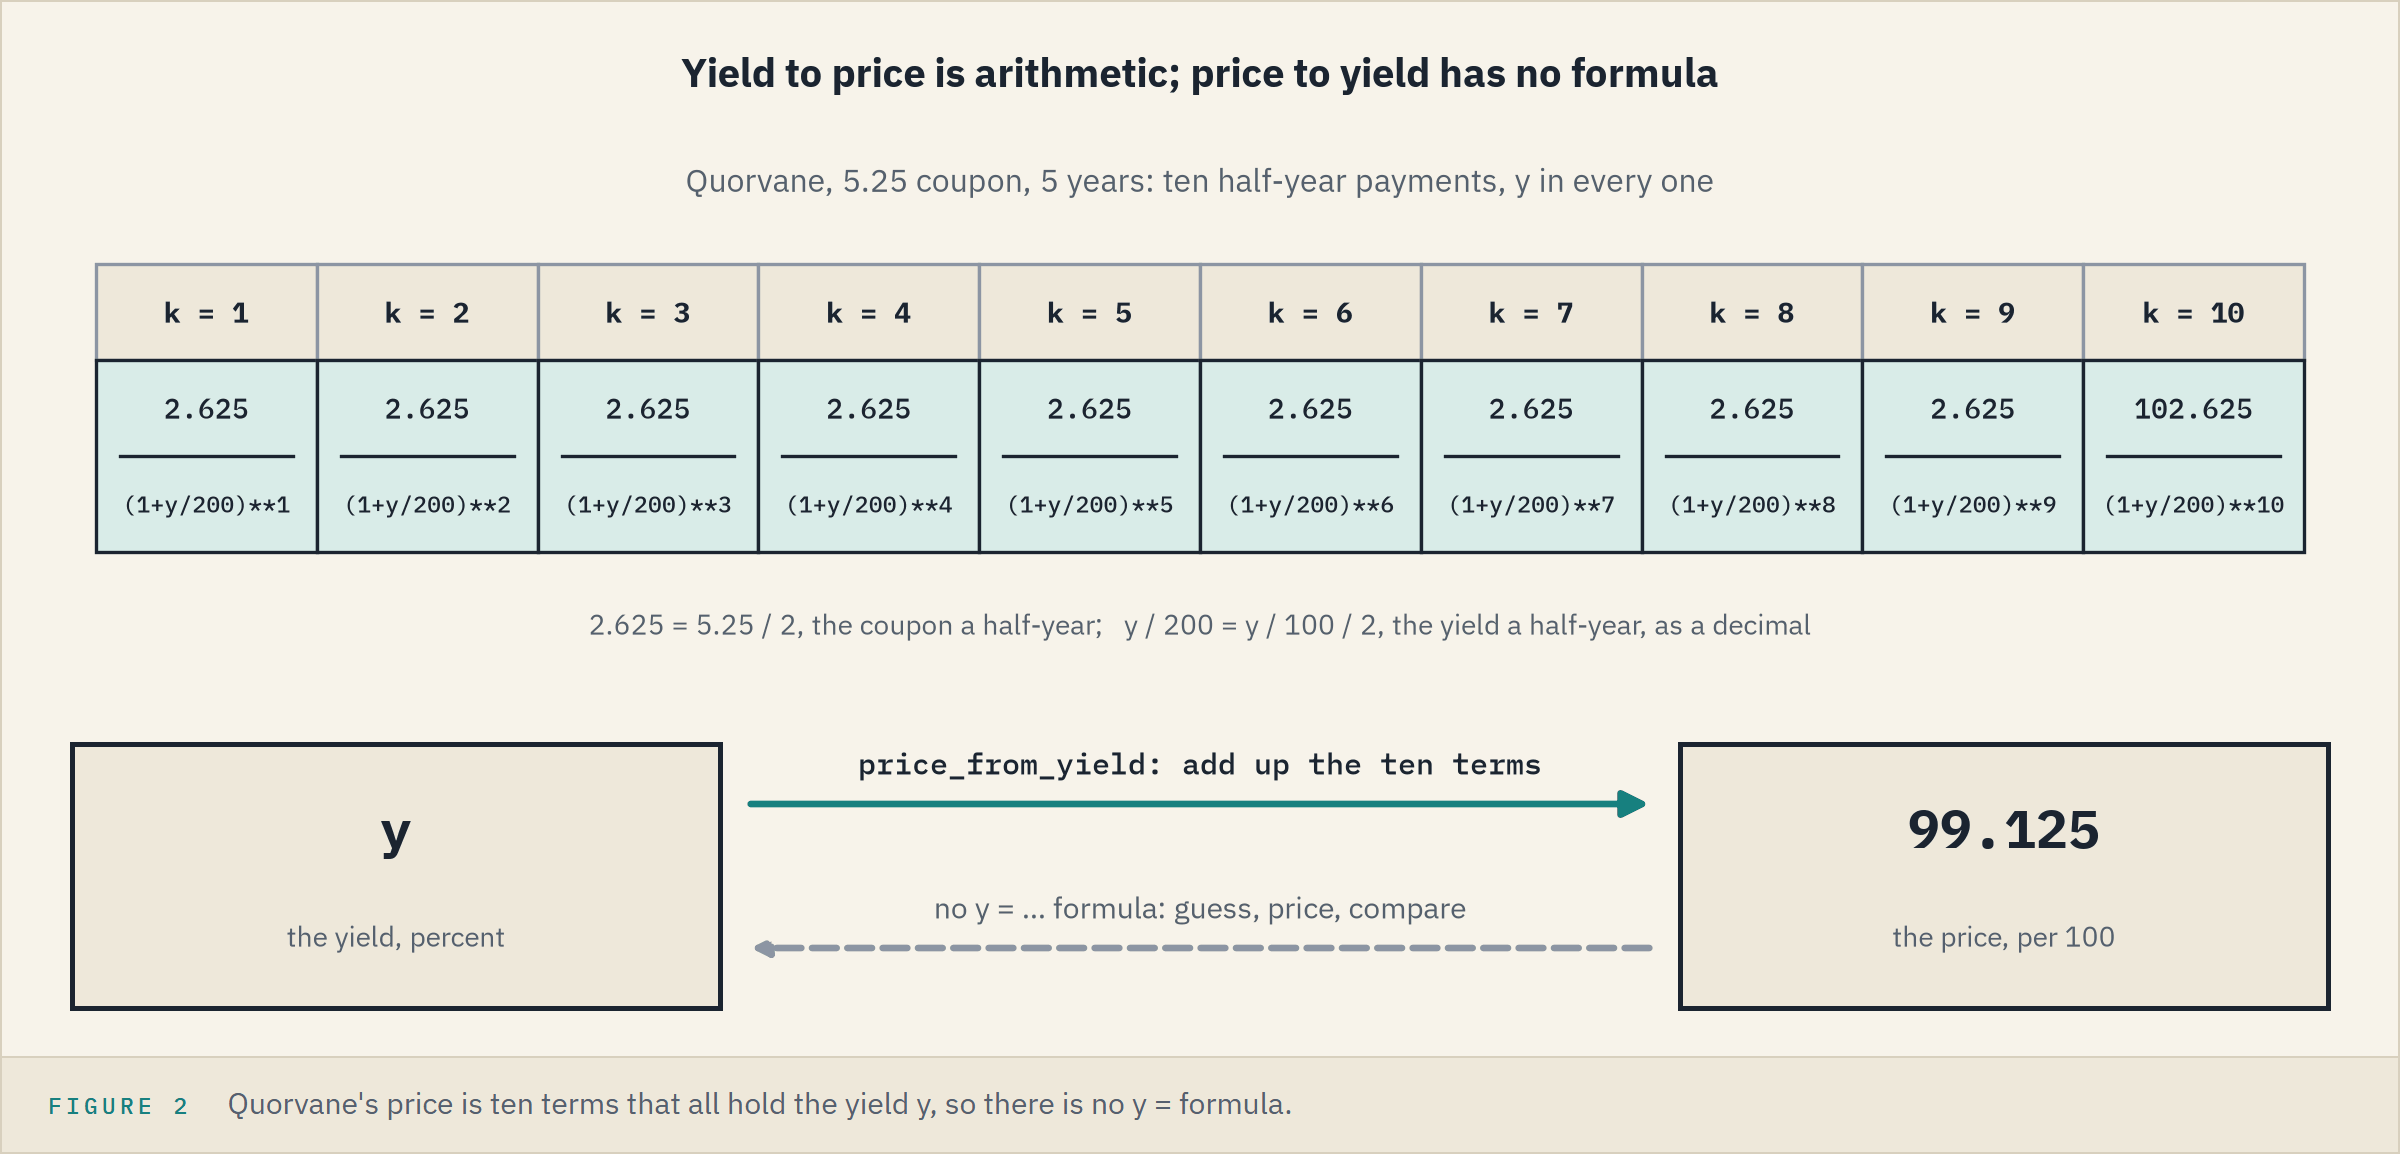

Given a yield, the ten terms are arithmetic: notebook 02's `price_from_yield`.
Given the price, the yield sits inside all ten, each to a different power, and no algebra rearranges them into `y = ...`.
So a yield is found by **search**: guess a yield, price it, compare with the quote, adjust.

### Guess, Price, Compare

Q. Guess five yields for Quorvane, price each, and compare with its quote of 99.125.

In [5]:
guesses = [5.0, 6.0, 5.5, 5.4, 5.45]
for guess_pct in guesses:
    # Quorvane: a 5.25 coupon, 5 years
    guess_price = bondmath.price_from_yield(5.25, guess_pct, 5)
    # price falls as yield rises: above the quote means the yield is above the guess
    side = 'above the quote, go higher' if guess_price > 99.125 else 'below the quote, go lower'
    print(f'{guess_pct:.2f} percent: price {guess_price:.4f}, {side}')

5.00 percent: price 101.0940, above the quote, go higher
6.00 percent: price 96.8012, below the quote, go lower
5.50 percent: price 98.9200, below the quote, go lower
5.40 percent: price 99.3503, above the quote, go higher
5.45 percent: price 99.1349, above the quote, go higher


After five guesses the yield sits between 5.45 and 5.50.

### Five Guesses on the Curve

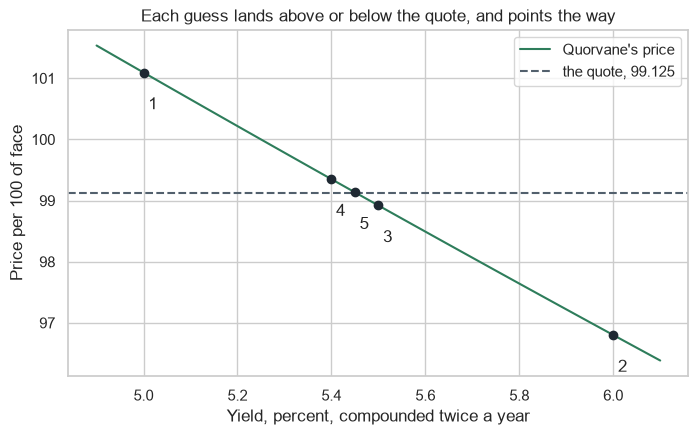

In [6]:
curve_yields = [4.9 + 0.01 * k for k in range(121)]
curve_prices = [bondmath.price_from_yield(5.25, y, 5) for y in curve_yields]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve_yields, curve_prices, label="Quorvane's price")
ax.axhline(99.125, color='#52606D', linestyle='--', label='the quote, 99.125')
for number, guess_pct in enumerate(guesses, start=1):
    guess_price = bondmath.price_from_yield(5.25, guess_pct, 5)
    ax.scatter(guess_pct, guess_price, color='#1F2933', zorder=3)
    ax.annotate(str(number), xy=(guess_pct, guess_price),
                xytext=(guess_pct + 0.01, guess_price - 0.6))
ax.set_title('Each guess lands above or below the quote, and points the way')
ax.set_xlabel('Yield, percent, compounded twice a year')
ax.set_ylabel('Price per 100 of face')
ax.legend()
plt.show()

Guesses 5 and 3, at 5.45 and 5.50, sit either side of the dashed line: the yield is where the line crosses the curve.

**Every guess says which way to go, because price falls as yield rises: that one fact is all a search needs.**

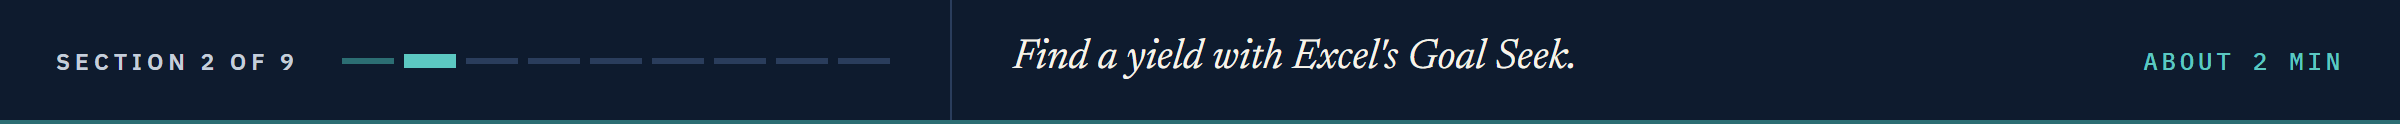

## 4.2 Goal Seek in Excel

Excel searches for you with **Goal Seek**: you name a cell holding a formula, the value it should show, and the cell Excel may change.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">A first guess</td><td align="left"><code>guesses[0]</code></td><td align="left"><code>5</code> in A1</td><td align="left"></td></tr>
<tr><td align="left">The price at the guess</td><td align="left"><code>bondmath.price_from_yield(5.25, guess_pct, 5)</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2031,9,30),5.25/100,A1/100,100,2,0)</code> in B1</td><td align="left"></td></tr>
<tr><td align="left">Guess until the price is the quote</td><td align="left">the five guesses</td><td align="left">Data, What-If Analysis, Goal Seek: Set cell <code>B1</code>, To value <code>99.125</code>, By changing cell <code>A1</code>, then OK</td><td align="left">A1 5.452248461259856, B1 99.12520671813279</td></tr>
</table>
<br clear="left">

### Where Goal Seek Stopped

Q. Started from 5 each time, how close did Goal Seek land on the four quotes?

In [7]:
tvm = pd.read_csv('bondmath_excel_reference_tvm.csv', index_col='case_id')
# what Goal Seek left in A1 and B1 for each quote, typed in from Excel
goal_seek = pd.DataFrame({
    'ticker': bonds['ticker'],
    'yield_pct': [5.452248461259856, 6.036363761470623, 4.435153807822778, 7.828571271933268],
    'price': [99.12520671813279, 100.50000082373151, 100.87535618968947, 97.75026237338443],
})
goal_seek['price_gap'] = goal_seek['price'] - bonds['quote']
# Excel's YIELD for the same quotes is a decimal in the file: times 100 for percent
excel_yield = tvm.loc['tvm_yield_01':'tvm_yield_04', 'excel_value']
goal_seek['excel_yield_pct'] = excel_yield.to_numpy() * 100
goal_seek['yield_gap_bp'] = (goal_seek['yield_pct'] - goal_seek['excel_yield_pct']) * 100
goal_seek.round(6)

,ticker,yield_pct,price,price_gap,excel_yield_pct,yield_gap_bp
0,QVNE,5.452248,99.125207,0.000207,5.452297,-0.004804
1,DNMR,6.036364,100.500001,0.000001,6.036364,-0.000015
2,PLWK,4.435154,100.875356,0.000356,4.435281,-0.012744
3,HLVF,7.828571,97.750262,0.000262,7.828610,-0.003889


Goal Seek lands close, not on the quote: Pellwick's price stops 0.000356 above it, and its yield 0.0127 bp from Excel's `YIELD`.
Start it from Quorvane's coupon, 5.25, and it stops somewhere else.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Start from the coupon</td><td align="left"></td><td align="left"><code>5.25</code> in A1, the same Goal Seek</td><td align="left">A1 5.452293509043892</td></tr>
</table>
<br clear="left">

**Where Goal Seek stops depends on where it starts: an answer key needs a search that stops where we say, every time.**

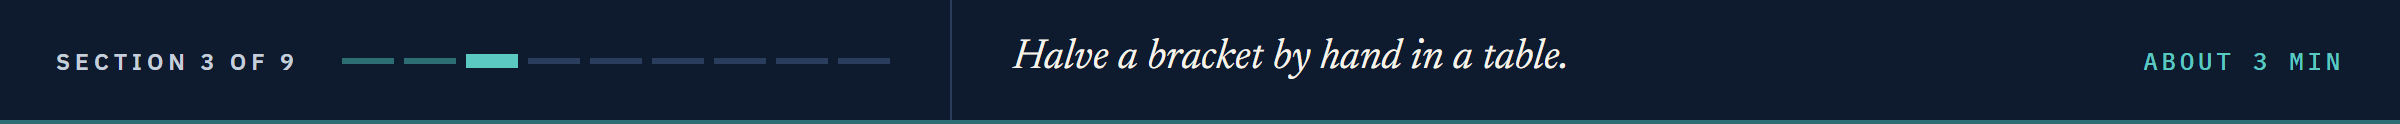

## 4.3 Bisection by Hand in a Table

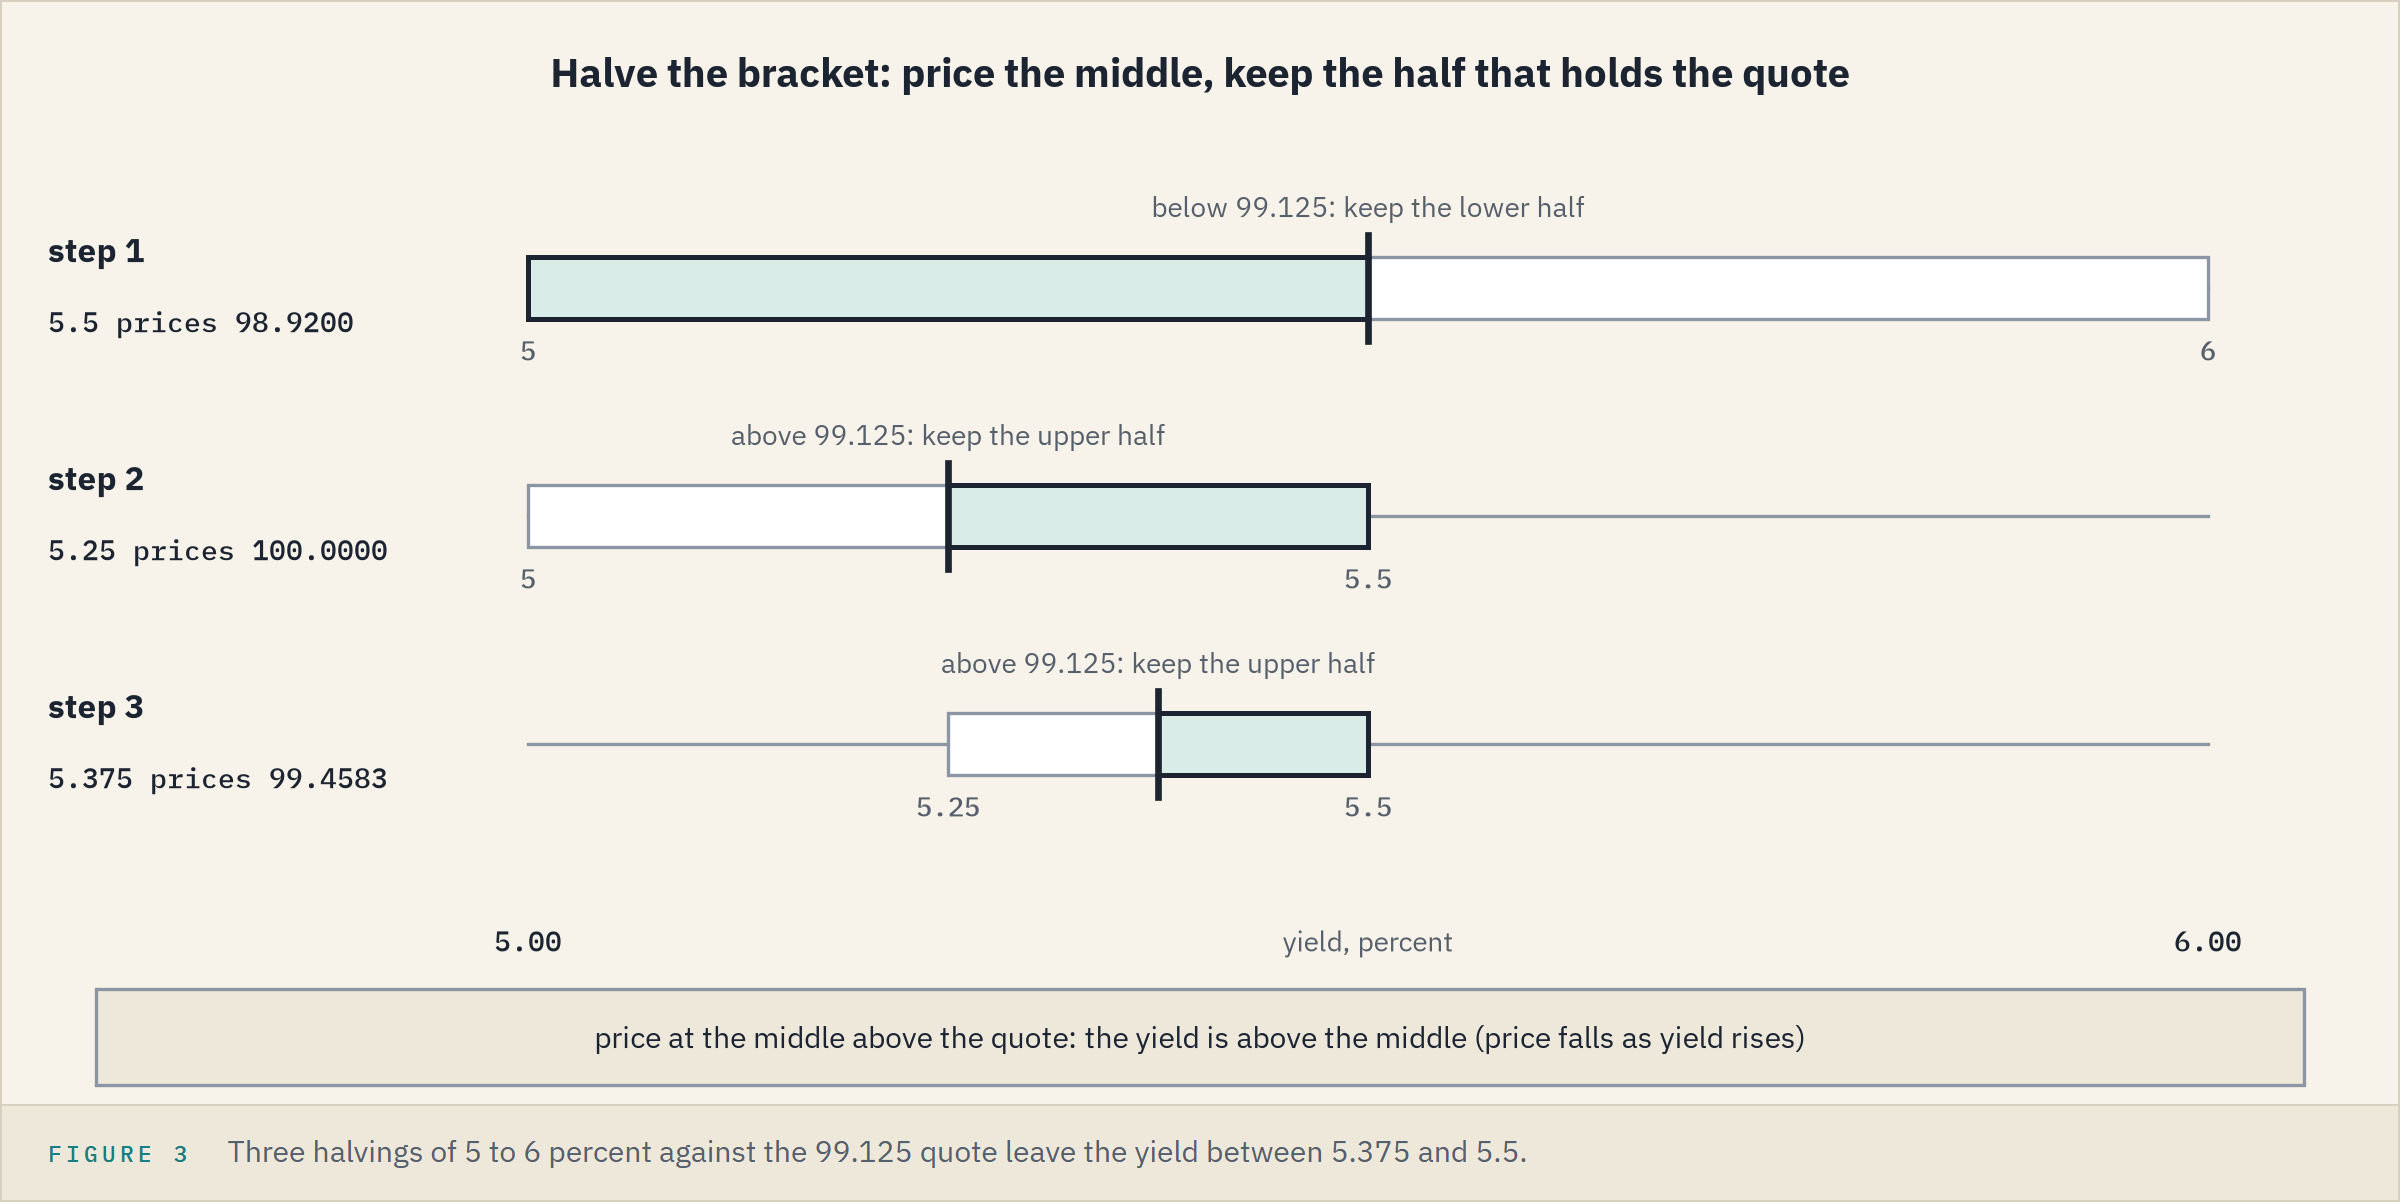

4.1's guesses put Quorvane's yield between 5 and 6 percent: call that the **bracket**.
Now guess the same way every time: price the middle, and keep the half that holds the quote.
Each step halves the bracket: **bisection**.

### Twelve Halvings

Q. Halve the bracket twelve times, one row per step.

In [8]:
low_pct, high_pct = 5.0, 6.0
rows = []
for step in range(1, 13):
    mid_pct = (low_pct + high_pct) / 2
    price_at_mid = bondmath.price_from_yield(5.25, mid_pct, 5)
    rows.append({'step': step, 'low_pct': low_pct, 'high_pct': high_pct, 'mid_pct': mid_pct,
                 'price_at_mid': price_at_mid})
    # above the quote: the yield is above the middle, so the middle is the new low end
    if price_at_mid > 99.125:
        low_pct = mid_pct
    else:
        high_pct = mid_pct
halving = pd.DataFrame(rows)
halving['width_bp'] = (halving['high_pct'] - halving['low_pct']) * 100

Q. What did each step keep?

In [9]:
formats = {'low_pct': '{:.6f}', 'high_pct': '{:.6f}', 'mid_pct': '{:.6f}',
           'price_at_mid': '{:.4f}', 'width_bp': '{:.4f}'}
halving.style.format(formats).hide(axis='index')

step,low_pct,high_pct,mid_pct,price_at_mid,width_bp
1,5.000000,6.000000,5.500000,98.9200,100.0000
2,5.000000,5.500000,5.250000,100.0000,50.0000
3,5.250000,5.500000,5.375000,99.4583,25.0000
4,5.375000,5.500000,5.437500,99.1887,12.5000
5,5.437500,5.500000,5.468750,99.0542,6.2500
6,5.437500,5.468750,5.453125,99.1214,3.1250
7,5.437500,5.453125,5.445312,99.1551,1.5625
8,5.445312,5.453125,5.449219,99.1382,0.7812
9,5.449219,5.453125,5.451172,99.1298,0.3906
10,5.451172,5.453125,5.452148,99.1256,0.1953


Steps 1 to 3 are the picture's.
The width halves every row, from 100 bp to 0.0488; the twelfth middle is 5.452393.

### The Bracket Closes

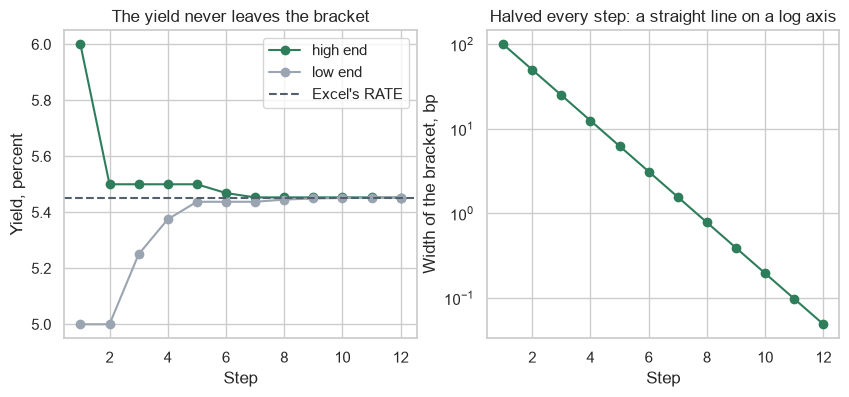

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(halving['step'], halving['high_pct'], marker='o', label='high end')
axes[0].plot(halving['step'], halving['low_pct'], marker='o', label='low end')
axes[0].axhline(tvm.loc['tvm_rate_11', 'excel_value'] * 100, color='#52606D', linestyle='--',
                label="Excel's RATE")
axes[0].set_title('The yield never leaves the bracket')
axes[0].set_xlabel('Step')
axes[0].set_ylabel('Yield, percent')
axes[0].legend()
axes[1].plot(halving['step'], halving['width_bp'], marker='o')
axes[1].set_yscale('log')
axes[1].set_title('Halved every step: a straight line on a log axis')
axes[1].set_xlabel('Step')
axes[1].set_ylabel('Width of the bracket, bp')
plt.show()

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The bracket</td><td align="left"><code>low_pct, high_pct = 5.0, 6.0</code></td><td align="left"><code>low_pct</code>, <code>high_pct</code>, <code>mid_pct</code>, <code>price_at_mid</code> in A1:D1, then 5 and 6 in A2:B2</td><td align="left"></td></tr>
<tr><td align="left">The middle, priced</td><td align="left"><code>mid_pct</code>, <code>price_at_mid</code></td><td align="left"><code>=(A2+B2)/2</code> in C2, <code>=PRICE(DATE(2026,9,30),DATE(2031,9,30),5.25/100,C2/100,100,2,0)</code> in D2</td><td align="left"></td></tr>
<tr><td align="left">Keep a half</td><td align="left"><code>if price_at_mid &gt; 99.125:</code></td><td align="left"><code>=IF(D2&gt;99.125,C2,A2)</code> in A3, <code>=IF(D2&gt;99.125,B2,C2)</code> in B3, C2:D2 copied to row 3, then A3:D3 filled down to row 31</td><td align="left">C13 5.452392578125, C31 5.452296503819525</td></tr>
</table>
<br clear="left">

**The bracket halves every step and the yield never leaves it: bisection cannot miss.**

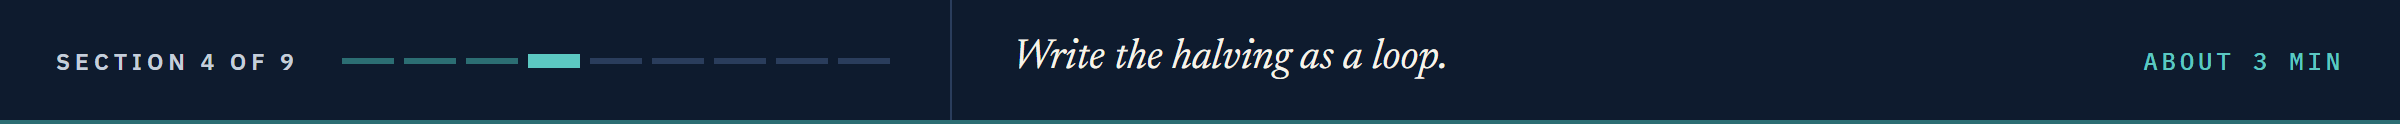

## 4.4 A `while` Loop That Halves the Bracket

Twelve steps came from `range(1, 13)`.
A better rule stops when the bracket is narrow enough, however many steps that takes: a `while` loop, from Course 1's Python for Fixed Income: Introduction, Part 2.

### Until Narrower Than 1e-10 Percent

Q. Halve until the bracket is narrower than 1e-10 percent, and count the steps.

In [11]:
low_pct, high_pct = 5.0, 6.0
steps = 0
# 1e-10 percent is a hundred-millionth of a basis point
while high_pct - low_pct > 1e-10:
    mid_pct = (low_pct + high_pct) / 2
    if bondmath.price_from_yield(5.25, mid_pct, 5) > 99.125:
        low_pct = mid_pct
    else:
        high_pct = mid_pct
    steps += 1
quorvane_yield_pct = (low_pct + high_pct) / 2
print(f'{steps} steps: Quorvane at 99.125 yields {quorvane_yield_pct:.8f} percent')

34 steps: Quorvane at 99.125 yields 5.45229650 percent


### Against Excel's RATE

In [12]:
# Excel's RATE for the same quote, a decimal in the file
excel_rate_pct = tvm.loc['tvm_rate_11', 'excel_value'] * 100
gap_bp = abs(quorvane_yield_pct - excel_rate_pct) * 100
print(f"Excel's RATE: {excel_rate_pct:.8f} percent, a gap of {gap_bp:.1e} bp")

Excel's RATE: 5.45229650 percent, a gap of 2.0e-08 bp


**Your loop lands on Excel's `RATE`: 5.45229650 percent, 2.0e-08 bp apart.**

**Predict 1**

Q. Start from -5 to 100 percent instead: a bracket 105 times wider, wide enough for any bond in the course.
How many halvings to get below 1e-10 percent?
Write down a number.

### A Bracket Wide Enough for Any Bond

In [13]:
low_pct, high_pct = -5.0, 100.0
steps = 0
while high_pct - low_pct > 1e-10:
    mid_pct = (low_pct + high_pct) / 2
    if bondmath.price_from_yield(5.25, mid_pct, 5) > 99.125:
        low_pct = mid_pct
    else:
        high_pct = mid_pct
    steps += 1
print(f'{steps} steps: {(low_pct + high_pct) / 2:.8f} percent')

40 steps: 5.45229650 percent


Only six more, and the same yield.
Each halving doubles the width a search can start from: six cover 64 times as wide, seven 128 times, and 105 sits between.
Six were enough because 34 steps had already taken the bracket to 5.8e-11 percent, well under the limit.

**Six more halvings pay for a bracket 105 times wider, so the module starts wide and needs no first guess.**

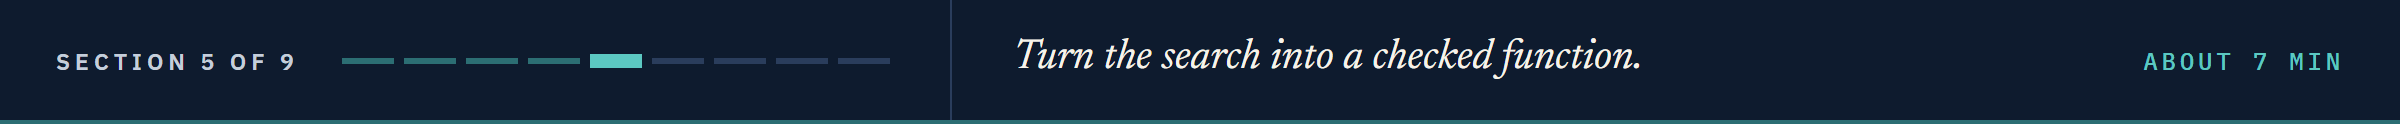

## 4.5 `yield_from_price` With a Check That Stops

Outside the bracket the loop still runs: it squeezes against one end and returns it, a wrong number with no warning.

### What the Bracket Can Explain

Q. What prices can a yield between -5 and 100 percent give Quorvane?

In [14]:
# the lowest yield gives the highest price, and the highest yield the lowest
highest_price = bondmath.price_from_yield(5.25, -5.0, 5)
lowest_price = bondmath.price_from_yield(5.25, 100.0, 5)
print(f'From {lowest_price:.4f} at 100 percent to {highest_price:.4f} at -5 percent')

From 6.8931 at 100 percent to 159.0631 at -5 percent


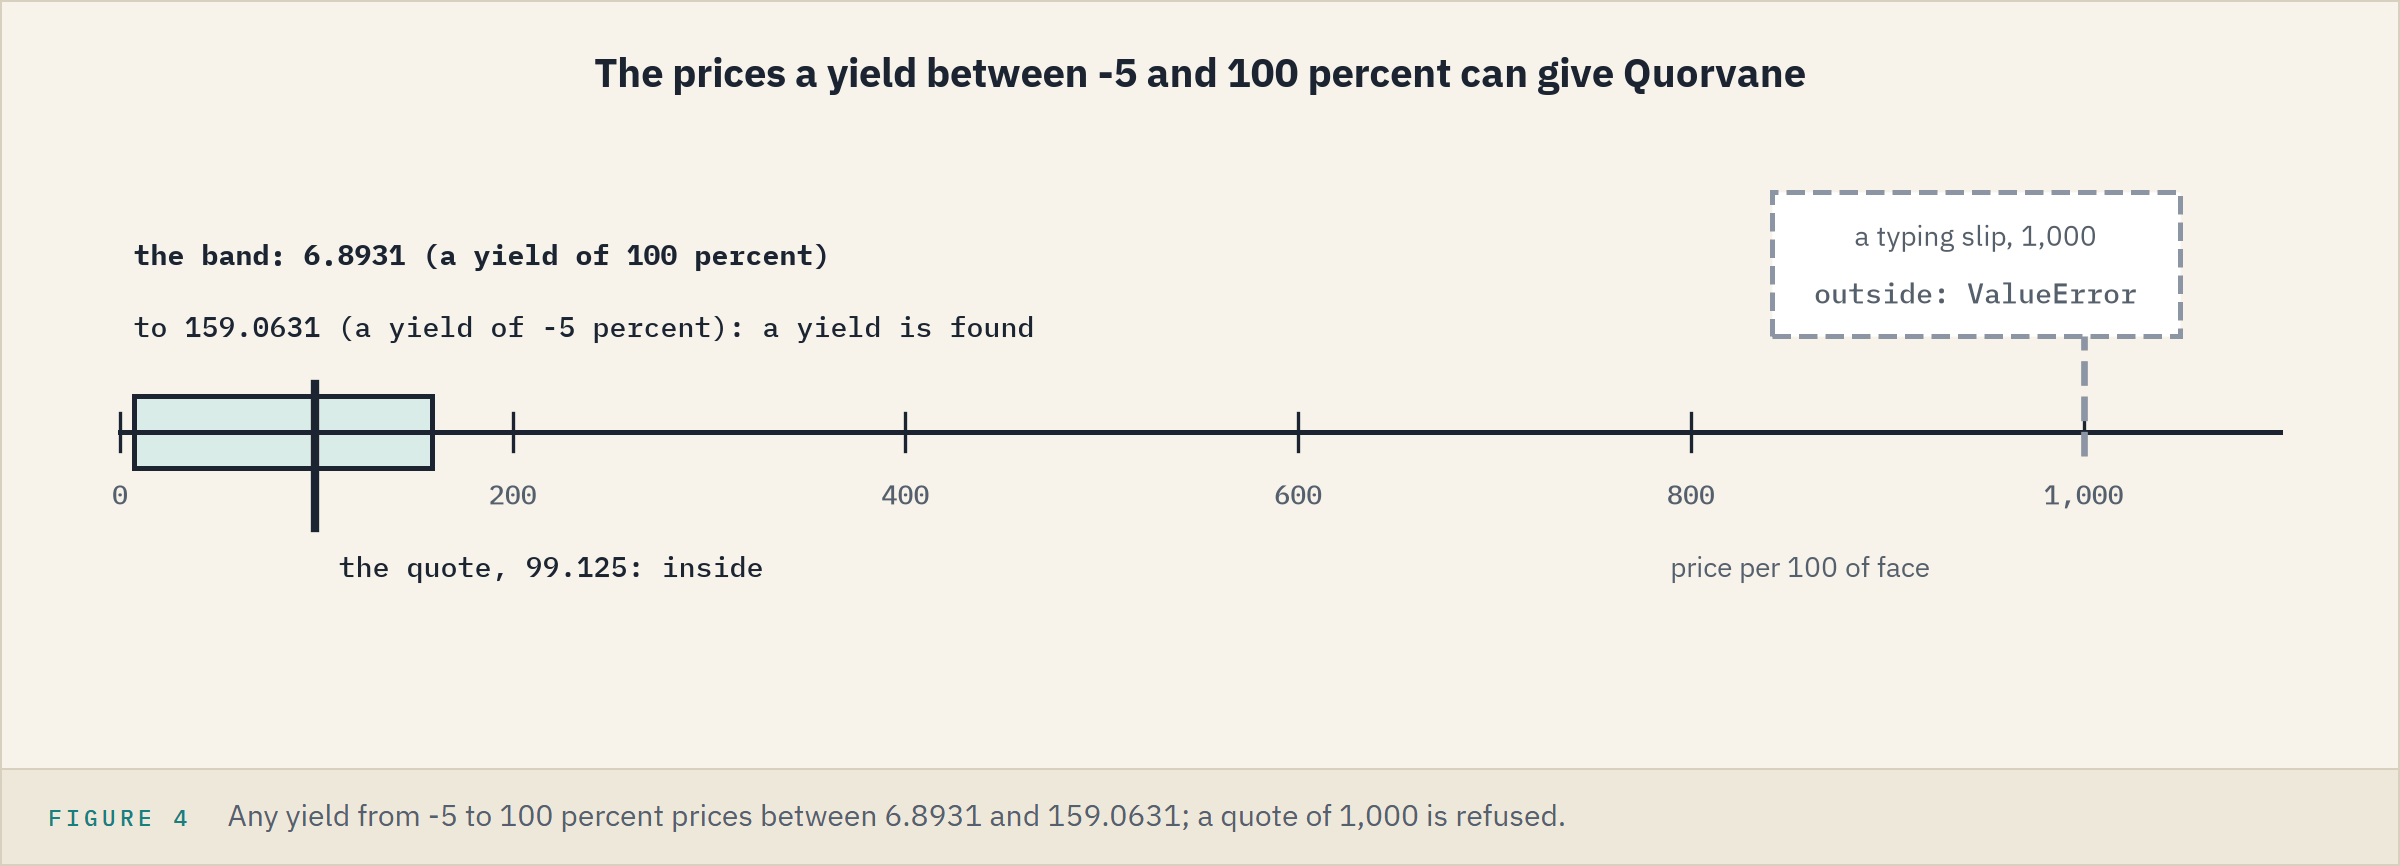

A price in the band has a yield in the bracket; a typing slip of 1,000 has none, and the function must say so.

### Append `yield_from_price`

Docstring first: the units, percent and per 100 in, percent out; the convention, compounded `frequency` times a year; the bracket and when the search stops; the `ValueError`; and Excel's route.
Then the check: `lowest_price <= price <= highest_price` is a **chained comparison**, true only when both `<=` hold, and `not` turns it round, so a price outside raises.
Then 4.4's loop.

In [15]:
%%writefile -a bondmath.py


def yield_from_price(coupon_pct: float, price: float, years: float, frequency: int = 2) -> float:
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.
    """
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price_from_yield(coupon_pct, mid_pct, years, frequency) > price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2

Appending to bondmath.py


### Reload and Solve the Four

In [16]:
import importlib

# read the file again: the module in memory has no yield_from_price yet
importlib.reload(bondmath)
bonds['yield_pct'] = [bondmath.yield_from_price(c, p, t)
                      for c, p, t in zip(bonds['coupon_pct'], bonds['quote'], bonds['years'])]
# Excel's RATE and YIELD for the same four quotes, decimals in the file
bonds['excel_rate_pct'] = tvm.loc['tvm_rate_11':'tvm_rate_14', 'excel_value'].to_numpy() * 100
bonds['excel_yield_pct'] = tvm.loc['tvm_yield_01':'tvm_yield_04', 'excel_value'].to_numpy() * 100
assert (bonds['yield_pct'] - bonds['excel_rate_pct']).abs().max() < 1e-6
assert (bonds['yield_pct'] - bonds['excel_yield_pct']).abs().max() < 1e-6
bonds[['ticker', 'coupon_pct', 'quote', 'yield_pct', 'excel_rate_pct', 'excel_yield_pct']].round(6)

,ticker,coupon_pct,quote,yield_pct,excel_rate_pct,excel_yield_pct
0,QVNE,5.250,99.125,5.452297,5.452297,5.452297
1,DNMR,6.125,100.500,6.036364,6.036364,6.036364
2,PLWK,4.750,100.875,4.435281,4.435281,4.435281
3,HLVF,7.500,97.750,7.828610,7.828610,7.828610


Three columns, one answer to the sixth decimal.

### Yield Beside Coupon

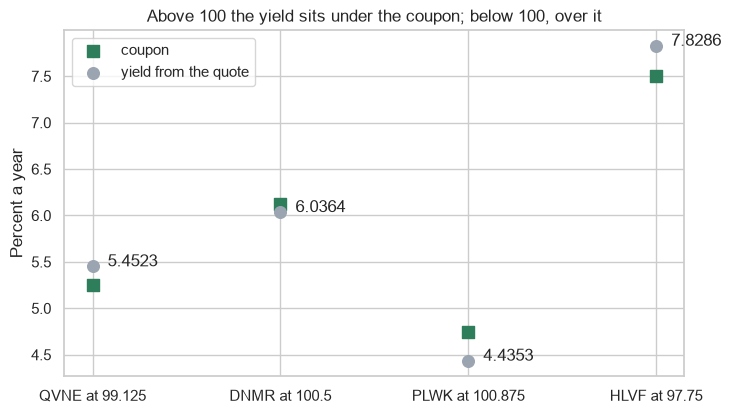

In [17]:
positions = range(len(bonds))
fig, ax = plt.subplots(figsize=(8, 4.5))
# marker='s' draws squares
ax.scatter(positions, bonds['coupon_pct'], marker='s', s=70, label='coupon')
ax.scatter(positions, bonds['yield_pct'], s=70, label='yield from the quote')
for position, yield_pct in zip(positions, bonds['yield_pct']):
    ax.text(position + 0.08, yield_pct, f'{yield_pct:.4f}')
labels = [f'{ticker} at {quote}' for ticker, quote in zip(bonds['ticker'], bonds['quote'])]
ax.set_xticks(positions, labels)
ax.set_title('Above 100 the yield sits under the coupon; below 100, over it')
ax.set_ylabel('Percent a year')
ax.legend()
plt.show()

Notebook 03's rule, read from the other side: Dunmarrow and Pellwick yield less than their coupons, Quorvane and Halvering more.

### A Price of 1,000

Q. What does a typing slip of 1,000 get?

In [18]:
bondmath.yield_from_price(5.25, 1000.0, 5)

ValueError: price 1000.0 is outside 6.893110 to 159.063092, the prices at yields of 100.0 and -5.0 percent

**Predict 2**

Q. Quorvane pays 126.25 in all, per 100 of face.
A buyer pays 130.00 for it.
What yield does the function return?

A) about -0.6 percent, the 3.75 lost spread over five years
B) about -2.9 percent, the 3.75 lost as a share of 130.00
C) about -3.8 percent, the 3.75 lost read as a percent

### Paid 130

In [19]:
print(f'Quorvane at 130.00: {bondmath.yield_from_price(5.25, 130.0, 5):.4f} percent')

Quorvane at 130.00: -0.6442 percent


A: a yield is a rate a year, so the loss spreads over the bond's life.
At a yield of 0 the price is the plain sum of the cash, 126.25, so any price above it needs a yield below 0: that is why the bracket starts at -5.

**Predict 3**

Q. Halve the price: a buyer pays 50.00 for Quorvane.
Near 99 it yields about 5.45 percent.
At 50?

A) about double, near 11 percent
B) far more than double
C) less than double, because the coupon stays the same

### Paid 50

In [20]:
print(f'Quorvane at 50.00: {bondmath.yield_from_price(5.25, 50.0, 5):.4f} percent')

Quorvane at 50.00: 22.3577 percent


B: the same coupons on half the money, and the money doubles when the 100 comes back.

**Excel side by side.** `RATE(nper, pmt, pv, fv)` takes the periods, the coupon a period, the price with a minus sign (money out, as notebook 01's `PV`), and the 100 back, and returns a rate a period, so `*2` makes it annual.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Yield from price, from periods</td><td align="left"><code>bondmath.yield_from_price(5.25, 99.125, 5)</code></td><td align="left"><code>=RATE(2*5,5.25/2,-99.125,100)*2</code></td><td align="left">0.05452296503527843</td></tr>
<tr><td align="left">Yield from price, from dates</td><td align="left">the same</td><td align="left"><code>=YIELD(DATE(2026,9,30),DATE(2031,9,30),5.25/100,99.125,100,2,0)</code></td><td align="left">0.054522965032957</td></tr>
<tr><td align="left">Paid 130</td><td align="left"><code>bondmath.yield_from_price(5.25, 130.0, 5)</code></td><td align="left"><code>=RATE(2*5,5.25/2,-130,100)*2*100</code></td><td align="left">-0.64422</td></tr>
<tr><td align="left">Paid 50</td><td align="left"><code>bondmath.yield_from_price(5.25, 50.0, 5)</code></td><td align="left"><code>=RATE(2*5,5.25/2,-50,100)*2*100</code></td><td align="left">22.35768</td></tr>
<tr><td align="left">A price of 1,000</td><td align="left"><code>ValueError</code></td><td align="left"><code>=YIELD(DATE(2026,9,30),DATE(2031,9,30),5.25/100,1000,100,2,0)*100</code></td><td align="left">-39.3451</td></tr>
<tr><td align="left">A price of 0</td><td align="left"><code>ValueError</code></td><td align="left"><code>=ISERROR(YIELD(DATE(2026,9,30),DATE(2031,9,30),5.25/100,0,100,2,0))</code></td><td align="left">TRUE</td></tr>
</table>
<br clear="left">

`YIELD` searches past -5 percent; the course's bracket is a desk's choice, treating a price that far from par as a typing slip.

**Four quotes, four yields that match Excel, and a price no yield in the bracket explains is refused.**

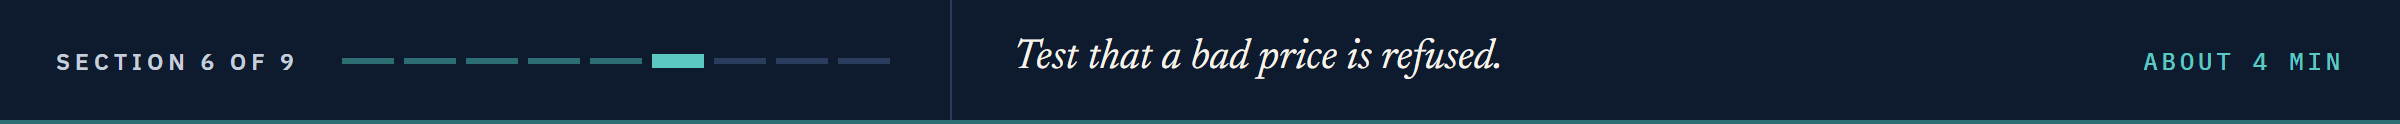

## 4.6 `pytest.raises`

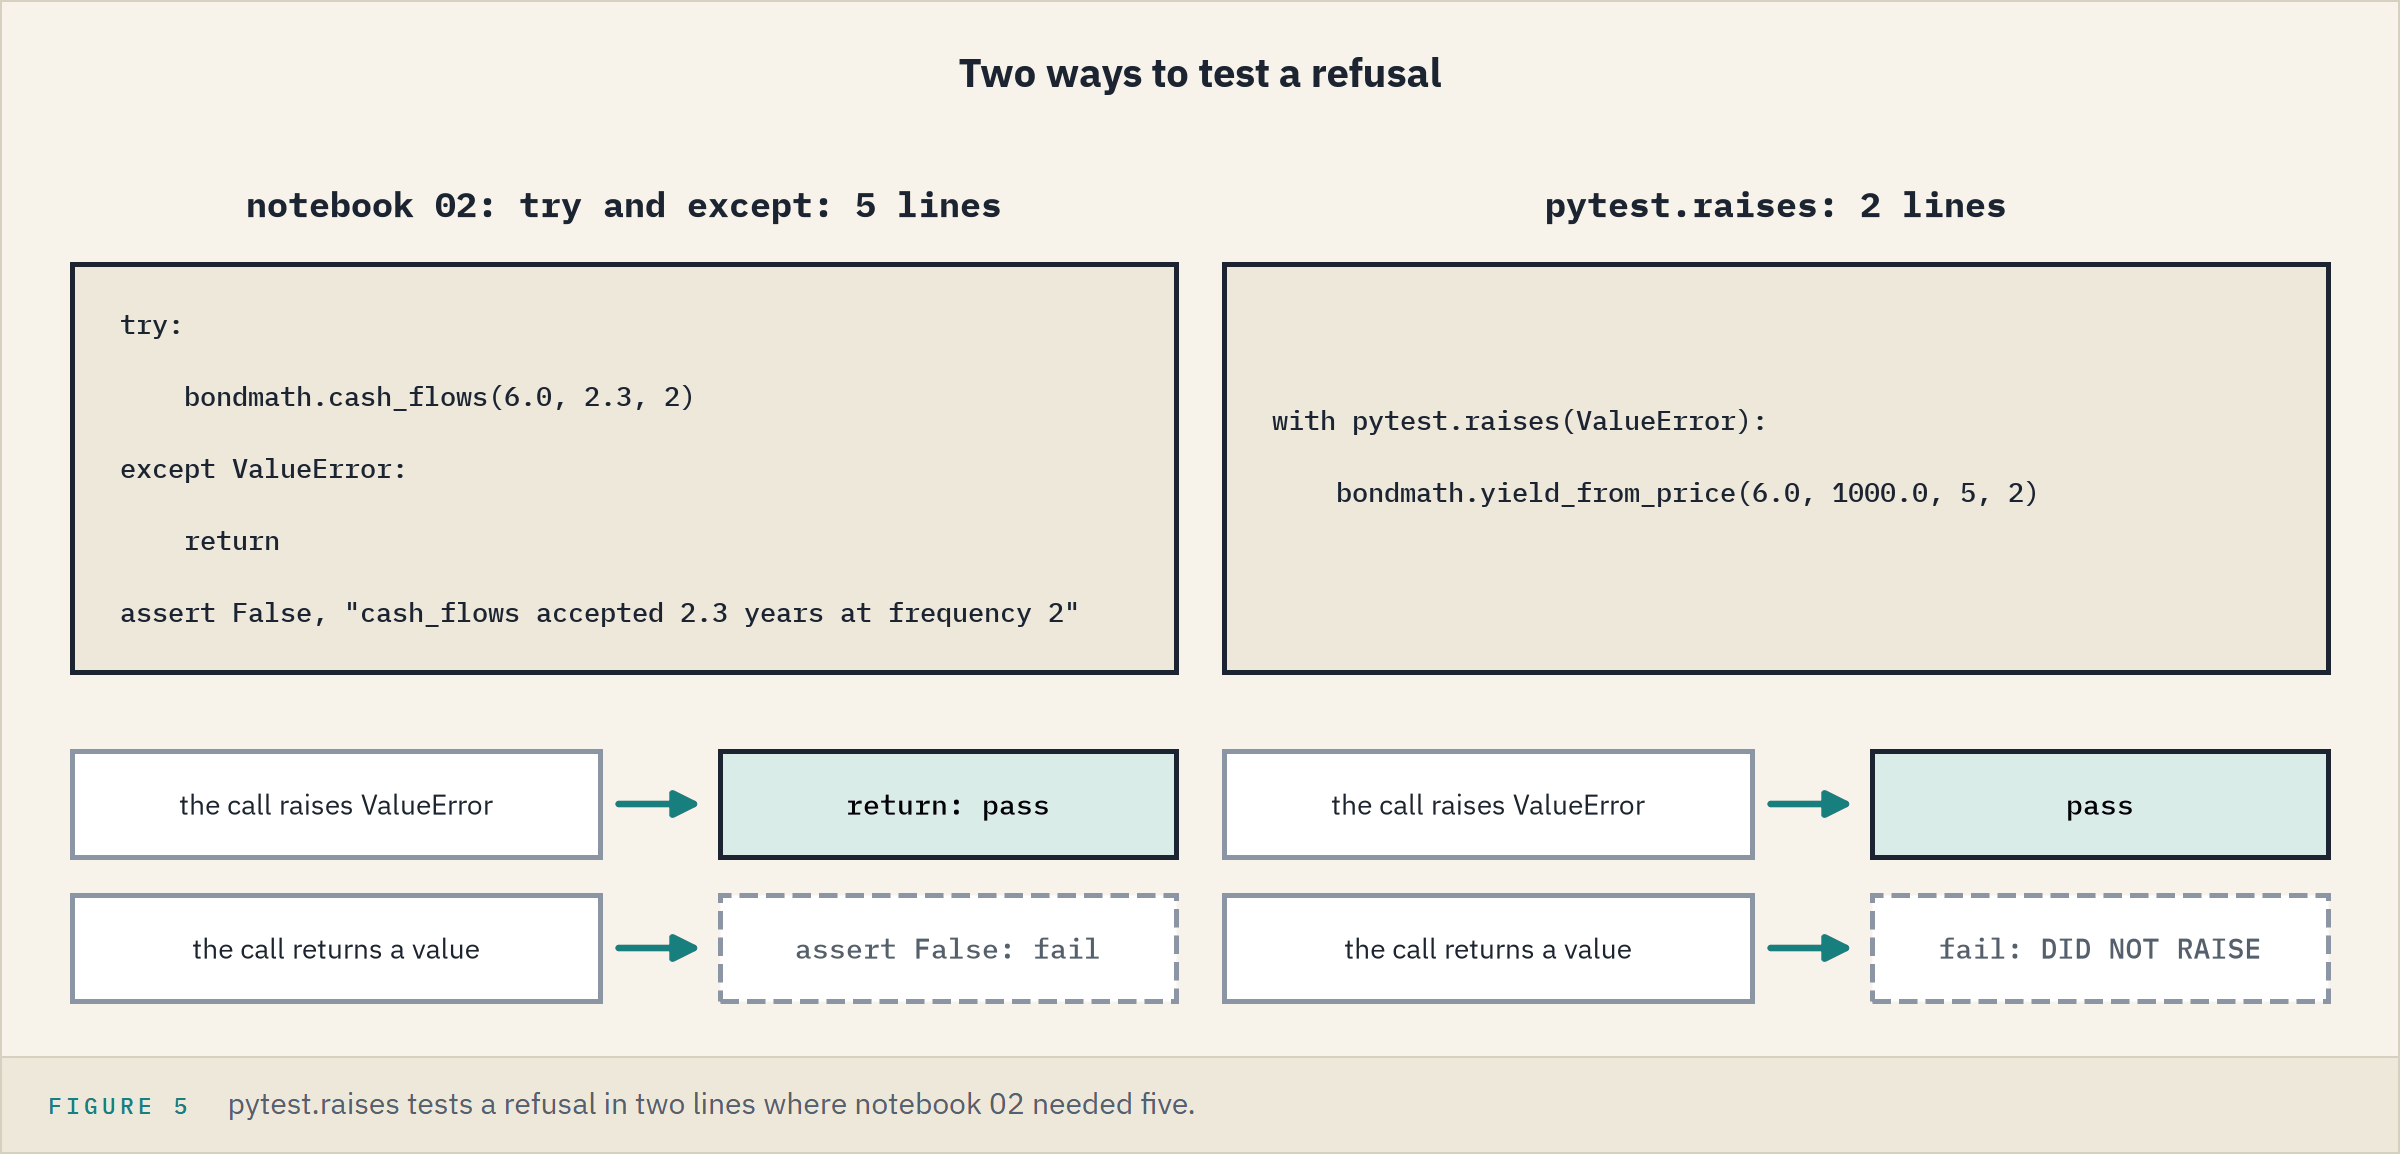

The refusal needs a test that passes only if the function raises.
`pytest.raises` says it in a `with` block, and `as caught` keeps the error: `caught.value` is the error itself.

### Catch the Error

In [21]:
import pytest

with pytest.raises(ValueError) as caught:
    bondmath.yield_from_price(5.25, 1000.0, 5)
print('Caught:', caught.value)

Caught: price 1000.0 is outside 6.893110 to 159.063092, the prices at yields of 100.0 and -5.0 percent


### When Nothing Is Raised

Q. And a price the bracket explains?

In [22]:
with pytest.raises(ValueError):
    bondmath.yield_from_price(5.25, 99.125, 5)

Failed: DID NOT RAISE ValueError

`DID NOT RAISE`: what a test will report if the refusal ever goes.

### Two Tests

The first reads Excel's 18 `RATE` rows; each row's formula multiplies `RATE` by the frequency, so its value is the annual yield as a decimal, and the expected value is that times 100.
It then keeps the coupon-date rows with notebook 02's filter; their `yield_pct_from_price` is Excel's `YIELD`, already in percent.
The second tests one price too high for any yield in the bracket and one too low.

In [23]:
%%writefile -a test_bondmath.py


def test_yield_from_price_matches_excel():
    # Excel's RATE, times the frequency, is the annual yield as a decimal
    for row in tvm_rows("RATE"):
        result = bondmath.yield_from_price(float(row["coupon_pct"]), float(row["price"]),
                                           float(row["years"]), int(row["frequency"]))
        assert result == pytest.approx(float(row["excel_value"]) * 100, abs=1e-6), row["case_id"]
    # Excel's YIELD on the coupon-date rows, already in percent in the reference file
    coupon_date_rows = [row for row in REFERENCE if row["coupdaybs"] == "0"]
    assert coupon_date_rows, "no coupon-date rows in the reference file"
    for row in coupon_date_rows:
        frequency = int(row["frequency"])
        years = int(row["coupnum"]) / frequency
        result = bondmath.yield_from_price(float(row["coupon_pct"]), float(row["price"]), years, frequency)
        assert result == pytest.approx(float(row["yield_pct_from_price"]), abs=1e-6), row["case_id"]


def test_yield_raises_outside_bracket():
    # no yield between -5 and 100 percent gives a price of 1,000 or of 0.01
    with pytest.raises(ValueError):
        bondmath.yield_from_price(6.0, 1000.0, 5, 2)
    with pytest.raises(ValueError):
        bondmath.yield_from_price(6.0, 0.01, 5, 2)

Appending to test_bondmath.py


In [24]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........                                                               [100%]
10 passed in 0.50s



### How Many Excel Numbers

In [25]:
reference = pd.read_csv('bondmath_excel_reference.csv')
rate_rows = tvm[tvm['function'] == 'RATE']
coupon_date_rows = reference[reference['coupdaybs'] == 0]
print(len(rate_rows), 'RATE rows and', len(coupon_date_rows), 'coupon-date YIELD rows')
print('Frequencies', sorted(coupon_date_rows['frequency'].unique().tolist()))

18 RATE rows and 17 coupon-date YIELD rows
Frequencies [1, 2, 4]


**`10 passed`: the module matches Excel on 35 rows, and a test now fails if the refusal ever goes.**

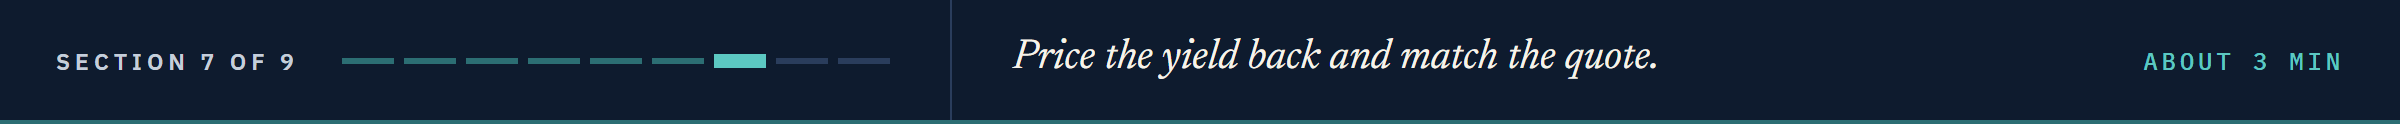

## 4.7 Price to Yield to Price, Round Trip

Two functions that undo each other can check each other.

### Yield, Price, Yield

Q. Price each bond at its issue yield from notebook 02, then solve the yield back.

In [26]:
trip = bonds[['ticker', 'coupon_pct', 'years']].copy()
trip['issue_yield_pct'] = [5.4, 6.125, 4.6, 7.7]
terms = list(zip(trip['coupon_pct'], trip['issue_yield_pct'], trip['years']))
trip['price'] = [bondmath.price_from_yield(c, y, t) for c, y, t in terms]
trip['yield_back_pct'] = [bondmath.yield_from_price(c, p, t)
                          for c, p, t in zip(trip['coupon_pct'], trip['price'], trip['years'])]
trip['gap_bp'] = (trip['yield_back_pct'] - trip['issue_yield_pct']) * 100
formats = {'issue_yield_pct': '{:.3f}', 'price': '{:.6f}', 'yield_back_pct': '{:.9f}',
           'gap_bp': '{:+.1e}'}
trip[['ticker', 'issue_yield_pct', 'price', 'yield_back_pct', 'gap_bp']].style.format(
    formats).hide(axis='index')

ticker,issue_yield_pct,price,yield_back_pct,gap_bp
QVNE,5.400,99.350327,5.400000000,+1.1e-09
DNMR,6.125,100.000000,6.125000000,-1.9e-09
PLWK,4.600,100.415887,4.600000000,-1.6e-09
HLVF,7.700,98.622736,7.700000000,+1.6e-09


### Quote, Yield, Quote

In [27]:
bonds['price_back'] = [bondmath.price_from_yield(c, y, t)
                       for c, y, t in zip(bonds['coupon_pct'], bonds['yield_pct'], bonds['years'])]
bonds['gap'] = bonds['price_back'] - bonds['quote']
bonds[['ticker', 'quote', 'price_back', 'gap']].style.format(
    {'quote': '{:.3f}', 'price_back': '{:.9f}', 'gap': '{:+.1e}'}).hide(axis='index')

ticker,quote,price_back,gap
QVNE,99.125,99.125000000,+1.4e-11
DNMR,100.500,100.500000000,+2.5e-10
PLWK,100.875,100.875000000,+5.2e-11
HLVF,97.750,97.750000000,-1.2e-10


Every yield comes back within 1.9e-09 bp and every quote within 2.5e-10 per 100; Goal Seek stopped up to 0.0004 away.

### The Round-Trip Test

The round trip proves the two functions agree with each other; Excel's rows prove they are right.

In [28]:
%%writefile -a test_bondmath.py


def test_yield_round_trip():
    # price a bond from a yield, then solve the yield back from that price
    bond_price = bondmath.price_from_yield(5.25, 6.1, 7, 2)
    assert bondmath.yield_from_price(5.25, bond_price, 7, 2) == pytest.approx(6.1, abs=1e-8)

Appending to test_bondmath.py


In [29]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........                                                              [100%]
11 passed in 0.50s



**Two functions that undo each other to nine decimals: the round trip proves they agree, Excel's rows that they are right.**

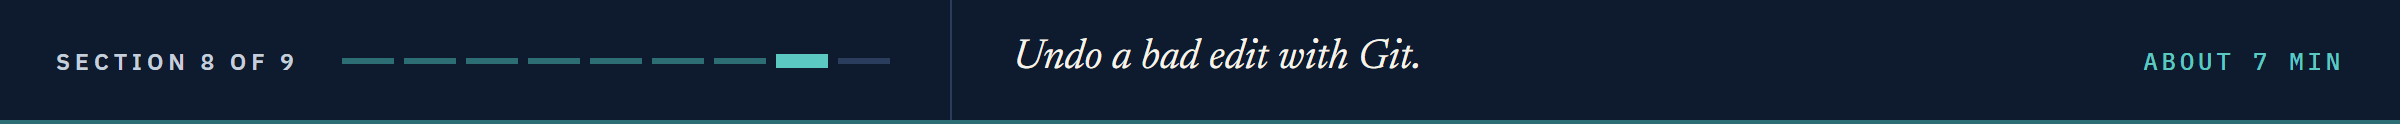

## 4.8 The Undo Button

A commit is a saved copy you can go back to, so commit first.

### What Changed

In [30]:
# --short: one line for each file Git sees as changed or new
!git -C "{work}" status --short
!git -C "{work}" diff --stat

 M bondmath.py
 M test_bondmath.py
?? __pycache__/
 bondmath.py      | 29 +++++++++++++++++++++++++++++
 test_bondmath.py | 30 ++++++++++++++++++++++++++++++
 2 files changed, 59 insertions(+)


` M` marks a file modified since the last commit.
`??` marks one Git does not track: `__pycache__`, the compiled copies Python keeps, which notebook 06 tells Git to ignore.

### Commit

In [31]:
subject = 'Notebook 04: yield_from_price'
body = 'Desks quote on price; the yield makes two quotes comparable'
!git -C "{work}" add bondmath.py test_bondmath.py
!git -C "{work}" commit -m "{subject}" -m "{body}"
!git -C "{work}" log --oneline

[main 07294a2] Notebook 04: yield_from_price
 2 files changed, 59 insertions(+)
07294a2 Notebook 04: yield_from_price
3f57cac Notebook 03: convert_yield
408a678 Notebook 02: cash_flows and price_from_yield
d029474 Notebook 01: future_value and present_value


### A Bad Edit

Suppose an edit, yours or an assistant's, tidies `yield_from_price` by deleting the check: no real bond yields outside -5 to 100 percent.
A string's `.index()` gives the position where a piece of text starts, as a list's `.index()` gave an item's in Course 1's Case Study: Organizing a Small Portfolio.

In [32]:
with open('bondmath.py', encoding='utf-8') as file:
    source = file.read()
# cut from the bracket's first price to the comment before the loop
start = source.index('    highest_price')
end = source.index('    # halve the bracket')
with open('bondmath.py', 'w', encoding='utf-8') as file:
    file.write(source[:start] + source[end:])
# the module in memory still has the check: reload it, then try 1,000
importlib.reload(bondmath)
print(f'A price of 1,000 now gets {bondmath.yield_from_price(5.25, 1000.0, 5):.4f} percent')

A price of 1,000 now gets -5.0000 percent


No error: -5.0000, the bottom of the bracket, the silent wrong number 4.5 warned of.

**Predict 4**

Q. Run the 11 tests on the edited file. How many fail?

A) none, the function still runs
B) one, `test_yield_raises_outside_bracket`
C) all three of today's

### Do the Tests Notice?

In [33]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', '--tb=no']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........F.                                                              [100%]
=========================== short test summary info ===========================
FAILED test_bondmath.py::test_yield_raises_outside_bracket - Failed: DID NOT RAISE ValueError
1 failed, 10 passed in 0.50s



B: the test you wrote today caught the edit, with 4.6's `DID NOT RAISE`.

### What the Edit Changed

In [34]:
!git -C "{work}" diff bondmath.py

diff --git a/bondmath.py b/bondmath.py
index 9210046..2b20afd 100644
--- a/bondmath.py
+++ b/bondmath.py
@@ -124,11 +124,6 @@ def yield_from_price(coupon_pct: float, price: float, years: float, frequency: i
     """
     # the bracket: price falls as yield rises, so the low yield gives the high price
     low_pct, high_pct = -5.0, 100.0
-    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
-    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
-    if not lowest_price <= price <= highest_price:
-        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
-                         f"the prices at yields of {high_pct} and {low_pct} percent")
     # halve the bracket until it is narrow enough
     while high_pct - low_pct > 1e-10:
         mid_pct = (low_pct + high_pct) / 2


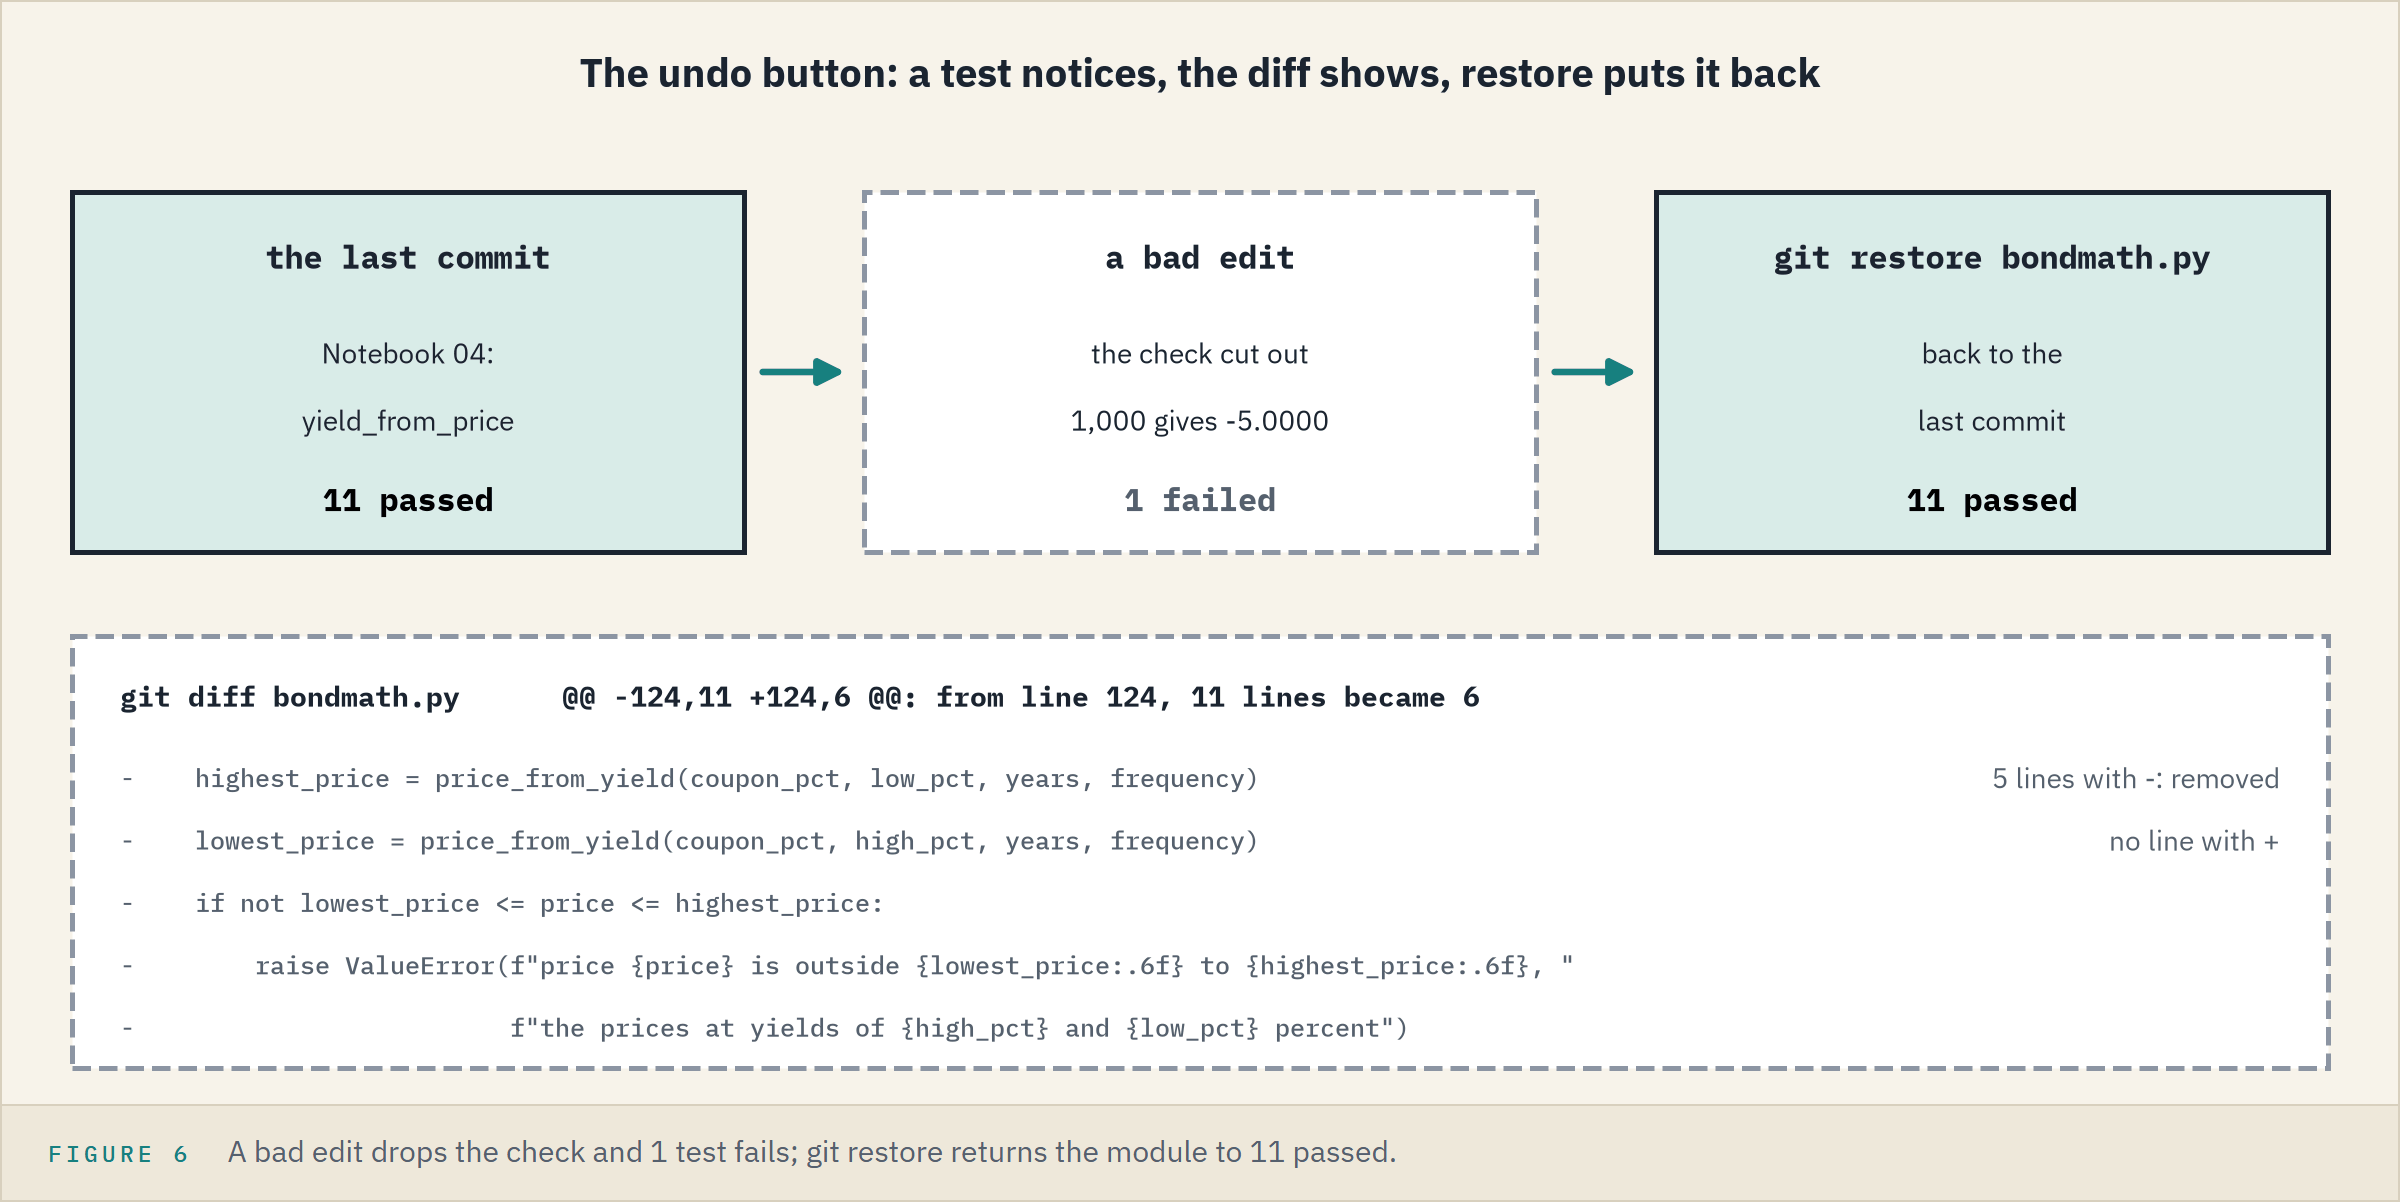

Five `-` lines and no `+`: the diff names exactly what the edit took.

### Put It Back

In [35]:
# restore: the file as it is in the last commit
!git -C "{work}" restore bondmath.py
!git -C "{work}" status --short

?? __pycache__/


No ` M` beside `bondmath.py`: it is the committed file again.
`git restore` throws the change away for good, so read the diff first.

**Excel side by side.** The nearest move in a workbook is to close it without saving: you are back at the last save.

### Tests Again

The module in memory still holds the edit, so reload it from the restored file first.

In [36]:
importlib.reload(bondmath)
with pytest.raises(ValueError) as caught:
    bondmath.yield_from_price(5.25, 1000.0, 5)
print('Refused again:', caught.value)

Refused again: price 1000.0 is outside 6.893110 to 159.063092, the prices at yields of 100.0 and -5.0 percent


In [37]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........                                                              [100%]
11 passed in 0.50s



**The test caught the edit, the diff showed it, and one command undid it: read the diff before you restore, because restore keeps nothing.**

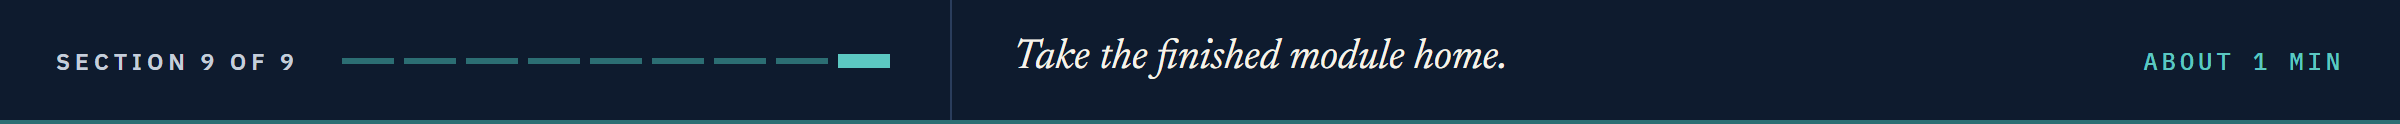

## Bring It Home

As in notebook 03, in a PowerShell terminal with the course's `.venv` active, with your own work folder.
The copy replaces your two files: anything you added by hand shows in `git diff --stat` as `-` lines, to read before you commit.

```powershell
# the work folder the setup cell printed
$work = "$env:TEMP\pfi_course2_04_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\bondmath.py", "$work\test_bondmath.py" .
python -m pytest -q
git diff --stat
git add bondmath.py test_bondmath.py
git commit -m "Notebook 04: yield_from_price" -m "Desks quote on price; the yield makes two quotes comparable"
git log --oneline
```

```
...........                                                              [100%]
11 passed in 0.50s
 bondmath.py      | 29 +++++++++++++++++++++++++++++
 test_bondmath.py | 30 ++++++++++++++++++++++++++++++
 2 files changed, 59 insertions(+)
```

The undo button works the same at home, before you commit:

```powershell
git status --short
git diff bondmath.py
git restore bondmath.py
```

In Colab, download the two `.py` files from the file browser on the left.
The work folder can stay: a restart makes a new one.

**`my_bondmath` holds six functions, eleven tests, and four commits.**

## You Can Now

By the end of this notebook, you can:

* Say why a yield has no formula, and why price falling as yield rises is all a search needs.
* Find a yield with Excel's Goal Seek, and say why its answer depends on where it starts.
* Halve a bracket by hand in Python and in a sheet, and say why bisection cannot miss.
* Write a `while` loop that stops when the bracket is narrow enough.
* Solve a yield from a price with `yield_from_price`, and in Excel with `RATE` and `YIELD`.
* Test a refusal with `pytest.raises`, and two functions against each other with a round trip.
* Undo a bad edit with `git status`, `git diff`, and `git restore`.

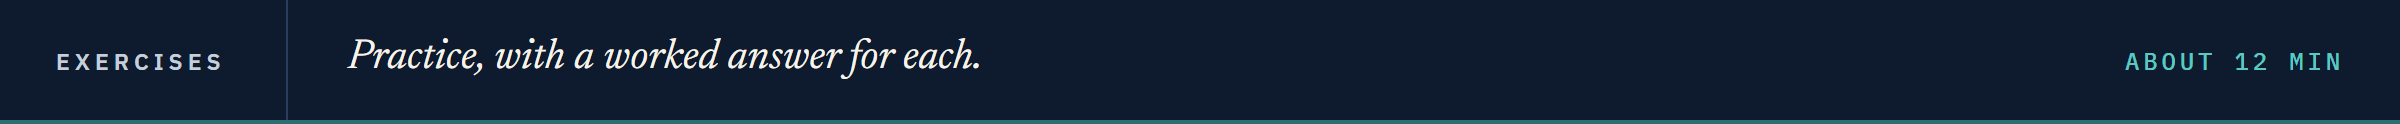

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The second desk's four bonds, now quoted on price on the same coupon date.
Replace each `...` with your own code, then run the cell.
Run the next two cells first: the bonds and `check`.

In [38]:
exercise_bonds = pd.DataFrame({
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'years': [4, 2, 6, 8],
    'quote': [99.5, 100.25, 98.375, 97.625],
})
exercise_bonds

,issuer,ticker,coupon_pct,years,quote
0,Ostrevale Telecom,OSTV,5.625,4,99.500
1,Tarnwick Utilities,TRNW,4.375,2,100.250
2,Osmere Chemicals,OSMC,5.000,6,98.375
3,Calderby Retail,CLDB,8.250,8,97.625


In [39]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

Q. With `bondmath.yield_from_price`, find each bond's yield from its quote. Store Osmere's, in percent and unrounded, in **ex1_osmere**, and the ticker of the highest yield in **ex1_highest**.

In [40]:
ex1_osmere = ...
ex1_highest = ...
check('Exercise 1 Osmere yield', ex1_osmere, 5.319909556762923)
check('Exercise 1 highest yield', ex1_highest, 'CLDB')

Exercise 1 Osmere yield: not attempted yet
Exercise 1 highest yield: not attempted yet


### Exercise 2

Q. Halvering's quote rises one point, from 97.75 to 98.75, and Pellwick's from 100.875 to 101.875. Store each yield's change in basis points, unrounded and negative for a fall, in **ex2_halvering_bp** and **ex2_pellwick_bp**, and in **ex2_larger** the ticker whose yield moves more, `'HLVF'` or `'PLWK'`. The quotes are what-ifs.

In [41]:
ex2_halvering_bp = ...
ex2_pellwick_bp = ...
ex2_larger = ...
check('Exercise 2 Halvering change', ex2_halvering_bp, -14.724150213623943)
check('Exercise 2 Pellwick change', ex2_pellwick_bp, -35.56528486387833)
check('Exercise 2 larger move', ex2_larger, 'PLWK')

Exercise 2 Halvering change: not attempted yet
Exercise 2 Pellwick change: not attempted yet
Exercise 2 larger move: not attempted yet


### Exercise 3

Q. Add `yield_change_bp(old_yield_pct, new_yield_pct)`, the change in basis points, positive for a rise. Write the docstring first: units, convention, and the Excel formula, `=(B1-A1)*100` with the old yield in A1 and the new in B1.
Add `test_yield_change_bp_cases`: two cases you can check by hand, and a check that Excel's `RATE` and `YIELD` put the same eight quotes less than 0.0001 bp apart: the last eight `tvm_rows("RATE")` rows beside the `tvm_rows("YIELD")` rows, by `zip`.
Write each in its cell below and run it once, run pytest, reload the module, and store the change from Quorvane's issue yield, 5.40, to its yield at 99.125, from `bondmath.yield_change_bp`, in **ex3_change**.

In [42]:
%%writefile -a bondmath.py


# Exercise 3: write yield_change_bp(old_yield_pct, new_yield_pct) below this line

Appending to bondmath.py


In [43]:
%%writefile -a test_bondmath.py


# Exercise 3: write test_yield_change_bp_cases() below this line

Appending to test_bondmath.py


In [44]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........                                                              [100%]
11 passed in 0.50s



In [45]:
# reload the module, then call your function
ex3_change = ...
check('Exercise 3 Quorvane yield change', ex3_change, 5.229650329247271)

Exercise 3 Quorvane yield change: not attempted yet


### Exercise 4: AI check

You gave an AI assistant `yield_from_price`'s docstring: the docstring is the prompt.
The function below came back; it runs, returns a number, and holds one convention error.

Before you run it: what should Quorvane at 99.125 yield?

4.5 has the number.

In [46]:
# written for this course in the style of an AI assistant's answer. It runs, and it holds one bug.
def assistant_yield_from_price(coupon_pct, price, years, frequency=2):
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in
    percent. Convention: the yield, compounded `frequency` times a year, at which price_from_yield
    equals price. Raises ValueError if the price is outside the prices at -5 and 100 percent.
    """
    # search the rate per period, in percent: the annual bracket divided by the frequency
    low_pct, high_pct = -5.0 / frequency, 100.0 / frequency
    highest_price = bondmath.price_from_yield(coupon_pct, low_pct * frequency, years, frequency)
    lowest_price = bondmath.price_from_yield(coupon_pct, high_pct * frequency, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f'price {price} is outside {lowest_price:.6f} to {highest_price:.6f}')
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        # price_from_yield takes the annual yield: the rate per period times the frequency
        if bondmath.price_from_yield(coupon_pct, mid_pct * frequency, years, frequency) > price:
            low_pct = mid_pct
        else:
            high_pct = mid_pct
    return (low_pct + high_pct) / 2


print(f'Quorvane at 99.125: {assistant_yield_from_price(5.25, 99.125, 5):.4f} percent')

Quorvane at 99.125: 2.7261 percent


Q. Test it against every `RATE` row before you trust it.

In [47]:
for case, coupon, quote, years, frequency, excel in zip(
        rate_rows.index, rate_rows['coupon_pct'], rate_rows['price'], rate_rows['years'],
        rate_rows['frequency'], rate_rows['excel_value']):
    result = assistant_yield_from_price(coupon, quote, years, frequency)
    # RATE times the frequency is a decimal a year; the docstring promises percent
    assert abs(result - excel * 100) < 1e-6, f'{case}: {result:.6f} against {excel * 100:.6f}'
print(f'All {len(rate_rows)} RATE rows match Excel')

AssertionError: tvm_rate_01: 2.821133 against 5.642266

Q. Find the convention the code broke, fix it in its cell, and run both cells again until every row matches. Store `assistant_yield_from_price(5.25, 99.125, 5)` in **ex4_quorvane** and the rows checked in **ex4_rows**.

In [48]:
ex4_quorvane = ...
ex4_rows = ...
check('Exercise 4 Quorvane yield', ex4_quorvane, 5.452296503292473)
check('Exercise 4 rows checked', ex4_rows, 18)

Exercise 4 Quorvane yield: not attempted yet
Exercise 4 rows checked: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">What each quote yields</td><td align="left">Quorvane 5.4523, Dunmarrow 6.0364, Pellwick 4.4353, Halvering 7.8286 percent</td></tr>
<tr><td align="left">How Excel gets there</td><td align="left">Goal Seek, up to 0.0004 from the quote; <code>RATE</code> and <code>YIELD</code>, to the sixth decimal</td></tr>
<tr><td align="left">The search in the module</td><td align="left"><code>yield_from_price</code>, 40 halvings from -5 to 100 percent</td></tr>
<tr><td align="left">Proved against Excel</td><td align="left"><code>11 passed</code>, 35 Excel rows within 1e-6 percent</td></tr>
<tr><td align="left">A price no yield explains</td><td align="left">a <code>ValueError</code>, pinned by <code>pytest.raises</code></td></tr>
<tr><td align="left">An edit that breaks it</td><td align="left">caught by a test, read in the diff, undone by <code>git restore</code></td></tr>
<tr><td align="left">Taken home</td><td align="left"><code>my_bondmath</code>, four commits</td></tr>
</table>
<br clear="left">

Be proud: you solved for a number that has no formula and proved it against Excel to a millionth of a percent.
Next, Case Study: A New Issue Calendar (notebook 05): eight re-offer prices turned into yields, and a workbook Excel calculates itself.

[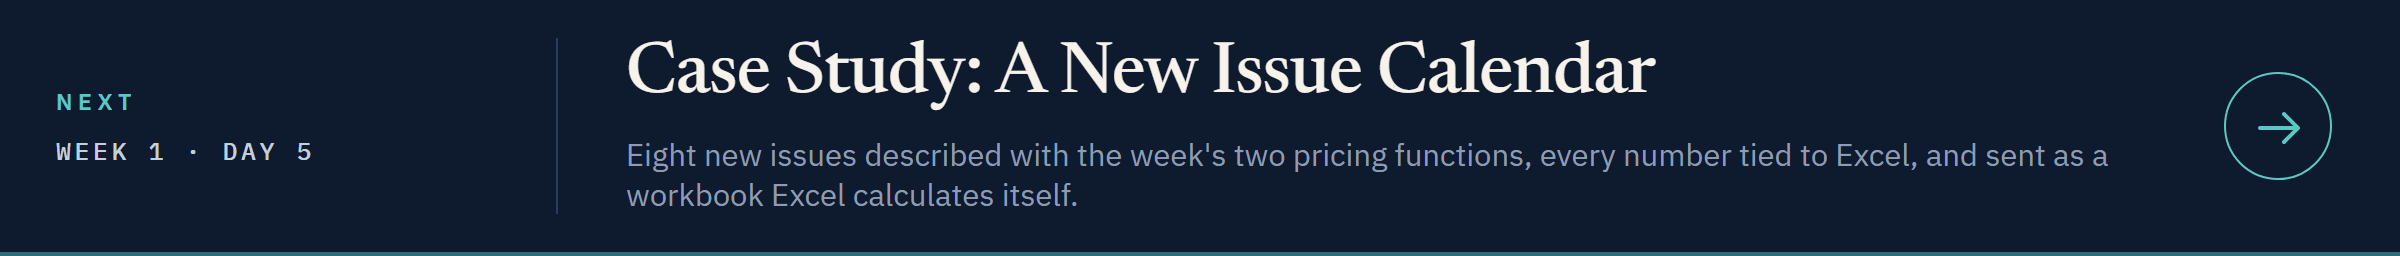](../day5/05_case_study_a_new_issue_calendar.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day5/05_case_study_a_new_issue_calendar.ipynb)